# Lab 06: Szyfr AES i tryby szyfrowania

# Część I: Advanced Encryption Standard

Advanced Encryption Standard (AES) to symetryczny szyfr blokowy, następca szyfru DES. Algorytm Rijndael został zgłoszony do konkursu NIST w 1998 roku, a w 2001 roku opublikowano go jako standard FIPS-197 (obowiązujący od 2002 roku).

AES jest oparty na algorytmie Rijndaela, którego autorami są belgijscy kryptografowie, Joan Daemen i Vincent Rijmen. Zaprezentowali oni swoją propozycję szyfru instytucji NIST w ramach ogłoszonego konkursu. NIST wybrał trzy algorytmy z rodziny Rijndaela, z których każdy miał tę samą wielkość bloku (128 bitów), ale miały różne długości klucza: 128, 192 i 256 bitów.

AES jest szyfrem opartym o sieć podstawieniowo-permutacyjną; **nie wykorzystuje sieci Feistela, a więc wszystkie operacje w algorytmie muszą mieć swoje wersje odwrotne**.

### Charakterystyka szyfru: 
1. AES jest szyfrem blokowym o rozmiarze bloku 128 bitów
2. AES może używać kluczy o długości 128, 192 i 256 bitów.
3. AES jest standardem NIST dla szyfrowania symetrycznego.
4. Nie jest znany żaden praktyczny atak na pełny AES — najlepszy znany atak (biclique) obniża złożoność złamania AES-128 jedynie do ok. $2^{126}$ operacji. NIST definiuje poziomy bezpieczeństwa, odnosząc je do siły algorytmu AES, np. poziom I NIST oznacza, że kryptosystem musi być co najmniej tak odporny na ataki jak AES-128, a poziom V — jak AES-256 (wyszukanie klucza wymaga ok. $2^{256}$ operacji).

W tym tutorialu zostanie przedstawiony wariant AES z kluczem o długości 128 bitów.

In [ ]:
# Funkcje pomocnicze
# W całym notebooku bajt to liczba całkowita od 0 do 255, a blok danych AES to lista 16 takich liczb.
# Postać binarną lub szesnastkową wypisujemy tylko po to, żeby zobaczyć dane.

def text_to_bytes(text):
    """ Tekst → lista bajtów (kodowanie UTF-8). """
    return list(text.encode("utf-8"))

def bytes_to_text(data):
    """ Lista bajtów → tekst (dekodowanie UTF-8). """
    return bytes(data).decode("utf-8")

def hex_to_bytes(hex_text):
    """ Napis szesnastkowy, np. "00ff10" → lista bajtów [0, 255, 16]. """
    result = []
    for i in range(0, len(hex_text), 2):
        result.append(int(hex_text[i : i + 2], 16))
    return result

def bytes_to_hex(data):
    """ Lista bajtów → napis szesnastkowy (po 2 cyfry na bajt). """
    text = ""
    for b in data:
        text = text + format(b, "02x")
    return text

def split_into_blocks(data):
    """ Dzieli listę bajtów na bloki po 16 bajtów (ostatni blok może być krótszy). """
    blocks = []
    for start in range(0, len(data), 16):
        blocks.append(data[start : start + 16])
    return blocks

def bytes_to_matrix(block):
    """ Blok 16 bajtów → stan 4x4 zgodnie z FIPS-197:
        state[r][c] = block[r + 4c], czyli bajty wypełniają stan KOLUMNAMI. """
    if len(block) != 16:
        raise ValueError("Blok AES musi mieć dokładnie 16 bajtów, a ma " + str(len(block)))
    state = []
    for r in range(4):
        row = []
        for c in range(4):
            row.append(block[r + 4 * c])
        state.append(row)
    return state

def matrix_to_bytes(state):
    """ Stan 4x4 → blok 16 bajtów (odczyt kolumnami): block[r + 4c] = state[r][c]. """
    block = []
    for c in range(4):
        for r in range(4):
            block.append(state[r][c])
    return block

def print_state(state):
    """ Wypisuje stan jako tabelę 4x4 liczb szesnastkowych. """
    for r in range(4):
        line = ""
        for c in range(4):
            line = line + format(state[r][c], "02x") + " "
        print("   ", line)

# ---------------------------------------------------------------------------
# Demonstracja: jak wiadomość tekstowa staje się danymi wejściowymi AES
# ---------------------------------------------------------------------------
message = "I've seen things you people wouldn't believe"
print("Wiadomość:", message)
print("Liczba znaków:", len(message))

# Krok 1: tekst → bajty. Każdy znak zamieniamy na bajt(y) według kodowania UTF-8.
data = text_to_bytes(message)
print()
print("Krok 1: tekst → bajty (UTF-8), liczba bajtów:", len(data))
for i in range(5):
    print("   znak", repr(message[i]), "→ bajt", data[i], "= 0x" + format(data[i], "02x"), "=", format(data[i], "08b"))
print("   ...")

# Krok 2: bajty → bloki po 16 bajtów (AES szyfruje bloki 128-bitowe = 16-bajtowe)
blocks = split_into_blocks(data)
print()
print("Krok 2: podział na bloki po 16 bajtów, liczba bloków:", len(blocks))
for i in range(len(blocks)):
    print("   blok", i, ":", bytes_to_hex(blocks[i]), " (" + str(len(blocks[i])) + " B)", repr(bytes_to_text(blocks[i])))
print("   Ostatni blok ma tylko", len(blocks[-1]), "B — przed szyfrowaniem trzeba go dopełnić (Zadanie 6, PKCS#7).")

# Krok 3: pierwszy blok → stan 4x4 (wypełnianie kolumnami)
state = bytes_to_matrix(blocks[0])
print()
print("Krok 3: blok 0 jako stan 4x4 (szesnastkowo):")
print_state(state)
print("Ten sam stan pokazany jako znaki — kolejne znaki tekstu wypełniają KOLUMNY:")
for r in range(4):
    line = ""
    for c in range(4):
        line = line + repr(chr(state[r][c])) + " "
    print("   ", line)

### **Przypomnienie: operacje w ciele skończonym Galois**

W algorytmie AES elementarna porcja informacji to 8 bitów (bajt), ale reprezentuje ona element ciała skończonego Galois GF($2^8$). Elementy tego ciała to wielomiany stopnia co najwyżej 7 o współczynnikach ze zbioru $\{0,1\}$, np.

$$
1010\,0101 \rightarrow x^7 + x^5 + x^2 + 1
$$


W ciele skończonym Galois są zdefiniowane operacje dodawania, odejmowania, mnożenia i dzielenia (z wyjątkiem dzielenia przez 0), które zwracają ośmiobitowe wyniki:
1. dodawanie (i odejmowanie) to po prostu XOR bitów,
2. mnożenie tak jak w arytmetyce wielomianów, ale wynik jest redukowany modulo nierozkładalny wielomian $p(x) = x^8 + x^4 + x^3 + x + 1$ (`0x11b`).

**Dlaczego potrzebujemy ciała?** GF($2^8$) jest ciałem więc każdy niezerowy element ma odwrotność multiplikatywną i dzięki temu wszystkie przekształcenia AES dają się odwrócić. Dodatkowo operacje działają na bajtach bez przeniesień, co pozwala na efektywną implementację.

#### Przykład: mnożenie w ciele GF($2^4$)

Zasadę najłatwiej zobaczyć na liczbach 4-bitowych. Ciało GF($2^4$) (16 elementów) budujemy, wybierając **nierozkładalny** wielomian stopnia 4 nad GF(2):

$$
m(x) = x^4 + x + 1 \qquad (\texttt{0b10011} = \texttt{0x13})
$$

Pomnóżmy $a = 1011 \rightarrow x^3 + x + 1$ (`0xB`) przez $b = 0110 \rightarrow x^2 + x$ (`0x6`).

**Krok 1 — mnożenie wielomianów** (współczynniki dodajemy modulo 2):

$$
(x^3 + x + 1)(x^2 + x) = x^5 + x^4 + x^3 + x^2 + x^2 + x = x^5 + x^4 + x^3 + x
$$

Wyrazy $x^2 + x^2$ znoszą się, bo $1 + 1 = 0$ w GF(2). Wynik (`111010`) ma stopień 5, więc nie jest elementem GF($2^4$) i trzeba go zredukować.

**Krok 2 — redukcja modulo $m(x)$.** W ciele zachodzi $x^4 \equiv x + 1$, więc $x^5 = x \cdot x^4 \equiv x^2 + x$:

$$
x^5 + x^4 + x^3 + x \equiv (x^2 + x) + (x + 1) + x^3 + x = x^3 + x^2 + x + 1
$$

To samo dzieleniem pisemnym — odejmowanie to XOR z odpowiednio przesuniętym $m(x)$:
```
  111010      a·b
^ 100110      m(x)·x
  ------
   11100
^  10011      m(x)
  ------
    1111      reszta (stopień < 4)
```

**Wynik:** $1011 \cdot 0110 = 1111$, czyli `0xB · 0x6 = 0xF` w GF($2^4$) z $m(x) = x^4 + x + 1$.

**Ten sam wynik daje algorytm z następnej komórki** (pętla 4 razy; redukcja przez XOR z `0b0011`, czyli $m(x)$ bez wyrazu $x^4$):

| krok | najmłodszy bit b | p | a po przesunięciu w lewo (i ewentualnej redukcji) |
|------|------------------|---|---------------------------------------------------|
| start | – | `0000` | `1011` |
| 1 | 0 | `0000` | `0110` ⊕ `0011` = `0101` (najstarszy bit a był 1) |
| 2 | 1 | `0000` ⊕ `0101` = `0101` | `1010` |
| 3 | 1 | `0101` ⊕ `1010` = `1111` | `0100` ⊕ `0011` = `0111` (najstarszy bit a był 1) |
| 4 | 0 | `1111` | `1110` |

W AES jest dokładnie tak samo, tylko w GF($2^8$): rolę $m(x)$ pełni $p(x) = x^8 + x^4 + x^3 + x + 1$, a stała redukcji to `0x1b`.

#### Mnożenie w ciele GF($2^8$)

Dodawanie to XOR (patrz wyżej). Mnożenie realizujemy algorytmem „`shift-and-add`” (dodawanie i przesuwanie). Przykład poniżej: 
1. Wejście: dwie ośmiobitowe liczby a, b
2. p = 0
3. Pętla (8 razy):
    * Jeżeli najmniej znaczący bit (low bit) liczby **b** == 1, to p = p ^ a
    * Przesuń a o jeden bit w lewo, usuwając najbardziej znaczący bit (high bit) i ustawiając najmniej znaczący bit na 0 (mnożenie przez $x$)
    * Jeśli przed przesunięciem bitowym (w poprzednim kroku) najbardziej znaczący bit a był ustawiony na 1, to a = a ^ 0x1b (redukcja modulo $p(x)$; `0x1b` to $p(x)$ bez wyrazu $x^8$)
    * Przesuń b o jeden bit w prawo, usuwając najmniej znaczący bit i ustawiając najbardziej znaczący bit na 0.
4. Zwróć p

In [ ]:
# funkcje pomocnicze dla operacji w ciele Galois
def gadd(a, b):
    return a ^ b

def gsub(a, b):
    return a ^ b

def gmul(a, b):
    p = 0
    for i in range(8):
        if b & 1 == 1:
            p = p ^ a
        prev_a = a
        a = (a << 1) % 256        
        hi_bit_set = prev_a & 0x80   #0x80 --> 10000000
        if hi_bit_set == 0x80:
            a = a ^ 0x1b
        b = b >> 1 
    return p
       
print(gadd(7,3)) #tutaj to po prostu XOR bitowy dwóch bajtów interpretowanych jako 7 i 3
print(gmul(7,3)) #tutaj to mnożenie, ale 7 i 3 to tylko reprezentacja dwóch bajtów 
                 #z których każdy jest w gruncie rzeczy reprezentacją wielomianów z GF(2^8) 

#### Dygresja: Tablice logarytmów i antylogarytmów (`ltable`, `atable`)

**Przypomnienie: logarytm a potęga.** Logarytm o podstawie $g$ to operacja odwrotna do potęgowania:

$$
\log_g x = p \iff g^p = x, \qquad \text{np. } \log_{10} 1000 = 3 \iff 10^3 = 1000.
$$

Stąd $g^{\log_g x} = x$ oraz $\log_g(g^p) = p$. Ponieważ $g^m \cdot g^n = g^{m+n}$, logarytm iloczynu jest sumą logarytmów: $\log_g(a \cdot b) = \log_g a + \log_g b$.

W GF($2^8$) obowiązują te same zależności, jeśli $g$ jest **generatorem** grupy cyklicznej $\mathrm{GF}(2^8)^{*}$ (np. $g =$ `0xe5`). Są przy tym trzy różnice: $x \ne 0$ (zero nie jest potęgą $g$), potęgi $g^p$ oblicza się w ciele, a wykładniki dodaje się modulo 255, bo $g^{255} = 1$. Tylko dla generatora $\log_g x$ istnieje dla każdego niezerowego $x$.

#### Logarytmy zmieniają mnożenie w dodawanie
**Przypomnienie: logarytm iloczynu jest sumą logarytmów**: 
$$\log(a \cdot b) = \log a + \log b,$$
bo $10^m \cdot 10^n = 10^{m+n}$ — przy mnożeniu potęg wykładniki się dodają. Mając tablicę logarytmów i tablicę odwrotną (potęg), można zastąpić mnożenie dodawaniem: odczytujemy logarytmy obu liczb, dodajemy je i odczytujemy, jaka liczba ma taki logarytm.

#### Szybsze mnożenie w ciele $GF(2^8)$

Funkcja `gmul` potrzebuje 8 iteracji pętli na każde mnożenie.  Szybciej można mnożyć, korzystając z faktu, że niezerowe elementy należące do GF($2^8$) tworzą **grupę cykliczną** rzędu 255 (czyli zawierającą 255 elementów bo 0 nie ma odwrotności multiplikatywnej). Ponieważ elementów grupy jest tylko 255 można wygenerować tablice pomocnicze. 

Dla grupy cyklicznej istnieje **generator grupy** $g$, czyli taki element tej grupy, którego kolejne potęgi $g^0, g^1, \dots, g^{254}$, obliczane w ciele GF($2^8$) (mnożeniem modulo $p(x) = x^8 + x^4 + x^3 + x + 1$, czyli `0x11b`, binarnie `1 0001 1011`), dają wszystkie 255 niezerowych elementów ciała. Wykładniki można przy tym redukować modulo 255, ponieważ $g^{255} = 1$.

Możemy przygotować tablice realizujące potęgowanie ($p \mapsto g^p$), oraz logarytmowanie ($x \mapsto p$). W poniższym przykładzie stosowany jest generator $g =$ `0xe5`. 

Generator `0xe5` ma postać:
- binarnie: `1110 0101`
- dziesiętnie: 229, bo $128 + 64 + 32 + 4 + 1 = 229$
- jako wielomian w $GF(2^8)$: $x^7 + x^6 + x^5 + x^2 + 1$

Algorytm szybkiego mnożenia używa dwóch tablic: 

- **`atable`** (potęgi, „exp”): `atable[k]` $= g^k$ — k-ta potęga generatora obliczona w GF($2^8$), np.
   - `atable[0] = 0x01` bo $g^0 = 1$,
   - `atable[1] = 0xe5` bo $g^1 = g$,
   - `atable[2] = gmul(0xe5, 0xe5) = 0x4c` czyli $g^2$.
     
Ponieważ $g^{255} = 1$, ostatni element `atable[255] = 0x01` powtarza pierwszy.
  
- **`ltable`** (logarytmy dyskretne): `ltable[a]` $= \log_g a$, czyli wykładnik $k$, dla którego $g^k = a$.
    - jest to tablica odwrotna do `atable`: `atable[ltable[a]] == a` dla każdego $a \ne 0$, np. `ltable[0xe5] = 1`.
    - dwie wartości w tej tablicy wymagają komentarza:
       - `ltable[0] = 0` logarytm zera nie istnieje (0 nie jest żadną potęgą $g$);
       - `ltable[1] = 255` zamiast 0 (obie wartości są równoważne modulo 255), dzięki czemu `255 - ltable[1] = 0` jest poprawnym indeksem tablicy.

**Sens algorytmu.** Tak jak zwykłe logarytmy zamieniają mnożenie na dodawanie, tak samo tutaj dla $a, b \ne 0$:

$$
a \cdot b = g^{\log_g a \,+\, \log_g b} \quad\Rightarrow\quad a \cdot b = \texttt{atable}[(\texttt{ltable}[a] + \texttt{ltable}[b]) \bmod 255]
$$

Zamiast 8 iteracji pętli wystarczą trzy odczyty z tablic i jedno dodawanie. Wykładniki dodajemy modulo 255, ponieważ $g^{255} = 1$.

Z tej samej zależności wynika **odwrotność multiplikatywna**, z której korzysta funkcja `gmul_inverse_tab` z Zadania 2 (a przez nią konstrukcja S-boksu): skoro $a \cdot a^{-1} = 1 = g^{255}$, to

$$
a^{-1} = g^{\,255 - \log_g a} = \texttt{atable}[255 - \texttt{ltable}[a]]
$$

Dla $a = 0$ odwrotność nie istnieje — w AES przyjmuje się umownie $0^{-1} = 0$ (stąd warunek w `gmul_inverse_tab`).

### Zadanie 1 — generowanie tablic `atable` i `ltable`

Napisz funkcję `generate_tables(g)`, która zwraca tablice `atable` i `ltable`. Jako `g` użyj `0xe5` (229).

**Podpowiedzi**
1. Do mnożenia w ciele używaj **wyłącznie** funkcji `gmul` zdefiniowanej wcześniej. 
2. **Tablica potęg** `atable`:
    - zacznij od listy `atable = [1]` (bo $g^0 = 1$),
    - dla `k = 1, 2, …, 255` dopisuj (`append`) wartość `gmul(atable[k-1], g)` (bo $g^k = g^{k-1} \cdot g$).

    Ostatni element `atable[255]` powinien wyjść równy 1, ponieważ $g^{255} = 1$.
   
3. **Tablica logarytmów** `ltable`:
    - utwórz listę 256 zer: `ltable = [0] * 256`,
    - dla `k = 1, 2, …, 255` wpisz `ltable[atable[k]] = k` (logarytm to wykładnik, dla którego $g^k$ daje daną wartość).

Po uruchomieniu komórki tablice są dostępne jako zmienne globalne `atable` i `ltable` — korzystają z nich funkcje z Zadania 2.


In [ ]:
def generate_tables(g=0xe5):
    """Zwraca (atable, ltable) dla generatora g grupy GF(2^8)*.
    atable[k] = g^k (k = 0…255),  ltable[a] = log_g(a) (a = 1…255)."""
    # === TODO uzupelnij implementacja ===
    
    return atable, ltable


atable, ltable = generate_tables(0xe5)


### Zadanie 2 — mnożenie i odwrotność z użyciem tablic

Napisz dwie funkcje, które zamiast pętli z funkcji `gmul` korzystają z tablic `atable` i `ltable`. 

**`gmul_tab(a, b)`** — iloczyn $a \cdot b$ w GF($2^8$):
1. Jeśli `a == 0` lub `b == 0`, zwróć `0` — logarytm zera nie istnieje, a iloczyn z zerem jest równy zero. Ten warunek musi być sprawdzony **przed** odczytem z `ltable`.
2. W przeciwnym razie odczytaj logarytmy: `ltable[a]` i `ltable[b]`.
3. Dodaj je **jako zwykłe liczby całkowite** i zredukuj sumę **modulo 255** (bo $g^{255} = 1$). Uwaga: to jest dodawanie wykładników w $\mathbb{Z}_{255}$, a nie XOR!
4. Zwróć `atable[suma]`.

**`gmul_inverse_tab(a)`** — odwrotność $a^{-1}$ w GF($2^8$):
1. Jeśli `a == 0`, zwróć `0` (umowa przyjęta w AES: $0^{-1} = 0$).
2. W przeciwnym razie skorzystaj z zależności $a^{-1} = g^{\,255 - \log_g a}$: oblicz indeks `(255 - ltable[a]) % 255` i zwróć `atable` pod tym indeksem. Redukcja `% 255` zabezpiecza przypadek `ltable[a] = 0` (np. gdyby ktoś przyjął `ltable[1] = 0`).

**Sprawdzenie** (komórka testowa poniżej):
- `gmul_tab(a, b) == gmul(a, b)` dla wszystkich par bajtów $a, b$,
- `gmul_tab(a, gmul_inverse_tab(a)) == 1` dla każdego $a = 1, \dots, 255$.

In [ ]:
def gmul_tab(a, b):
    """Iloczyn a·b w GF(2^8) obliczony z użyciem tablic potęg i logarytmów."""
    # === TODO uzupełnij implementację ===

    return wynik


def gmul_inverse_tab(a):
    """Odwrotność multiplikatywna a w GF(2^8) (dla a = 0 zwraca 0)."""
    # === TODO uzupełnij implementację ===

    return wynik


In [ ]:
# Testy Zadań 1 i 2
# Zadanie 1: tablice potęg i logarytmów
if len(atable) == 256 and atable[0] == 1 and atable[1] == 0xe5 and atable[255] == 1:
    print("✅ atable: atable[0] = 1, atable[1] = 0xe5, atable[255] = 1")
else:
    print("❌ atable: sprawdź długość (256) i wartości atable[0], atable[1], atable[255]")

bledy = 0
for a in range(1, 256):
    if atable[ltable[a]] != a:
        bledy = bledy + 1
if bledy == 0:
    print("✅ ltable: atable[ltable[a]] == a dla a = 1…255")
else:
    print("❌ ltable: liczba błędów:", bledy)

# Zadanie 2: mnożenie i odwrotność z tablic
bledy = 0
for a in range(256):
    for b in range(256):
        if gmul_tab(a, b) != gmul(a, b):
            bledy = bledy + 1
if bledy == 0:
    print("✅ gmul_tab(a, b) == gmul(a, b) dla wszystkich par bajtów")
else:
    print("❌ gmul_tab: liczba błędnych iloczynów:", bledy)

bledy = 0
for a in range(1, 256):
    if gmul_tab(a, gmul_inverse_tab(a)) != 1:
        bledy = bledy + 1
if bledy == 0 and gmul_inverse_tab(0) == 0:
    print("✅ gmul_inverse_tab: a · a^-1 = 1 dla a = 1…255 oraz 0^-1 = 0")
else:
    print("❌ gmul_inverse_tab: liczba błędów:", bledy, " gmul_inverse_tab(0) =", gmul_inverse_tab(0))


## S-Box czyli gdzie potrzebne są elementy odwrotne z $GF(2^8)$
Podobnie jak DES, AES używa S-boksów. S-box wprowadza do szyfru nieliniowość — bez niej cały szyfr byłby przekształceniem afinicznym nad GF(2) i dałby się złamać rozwiązaniem układu równań liniowych.

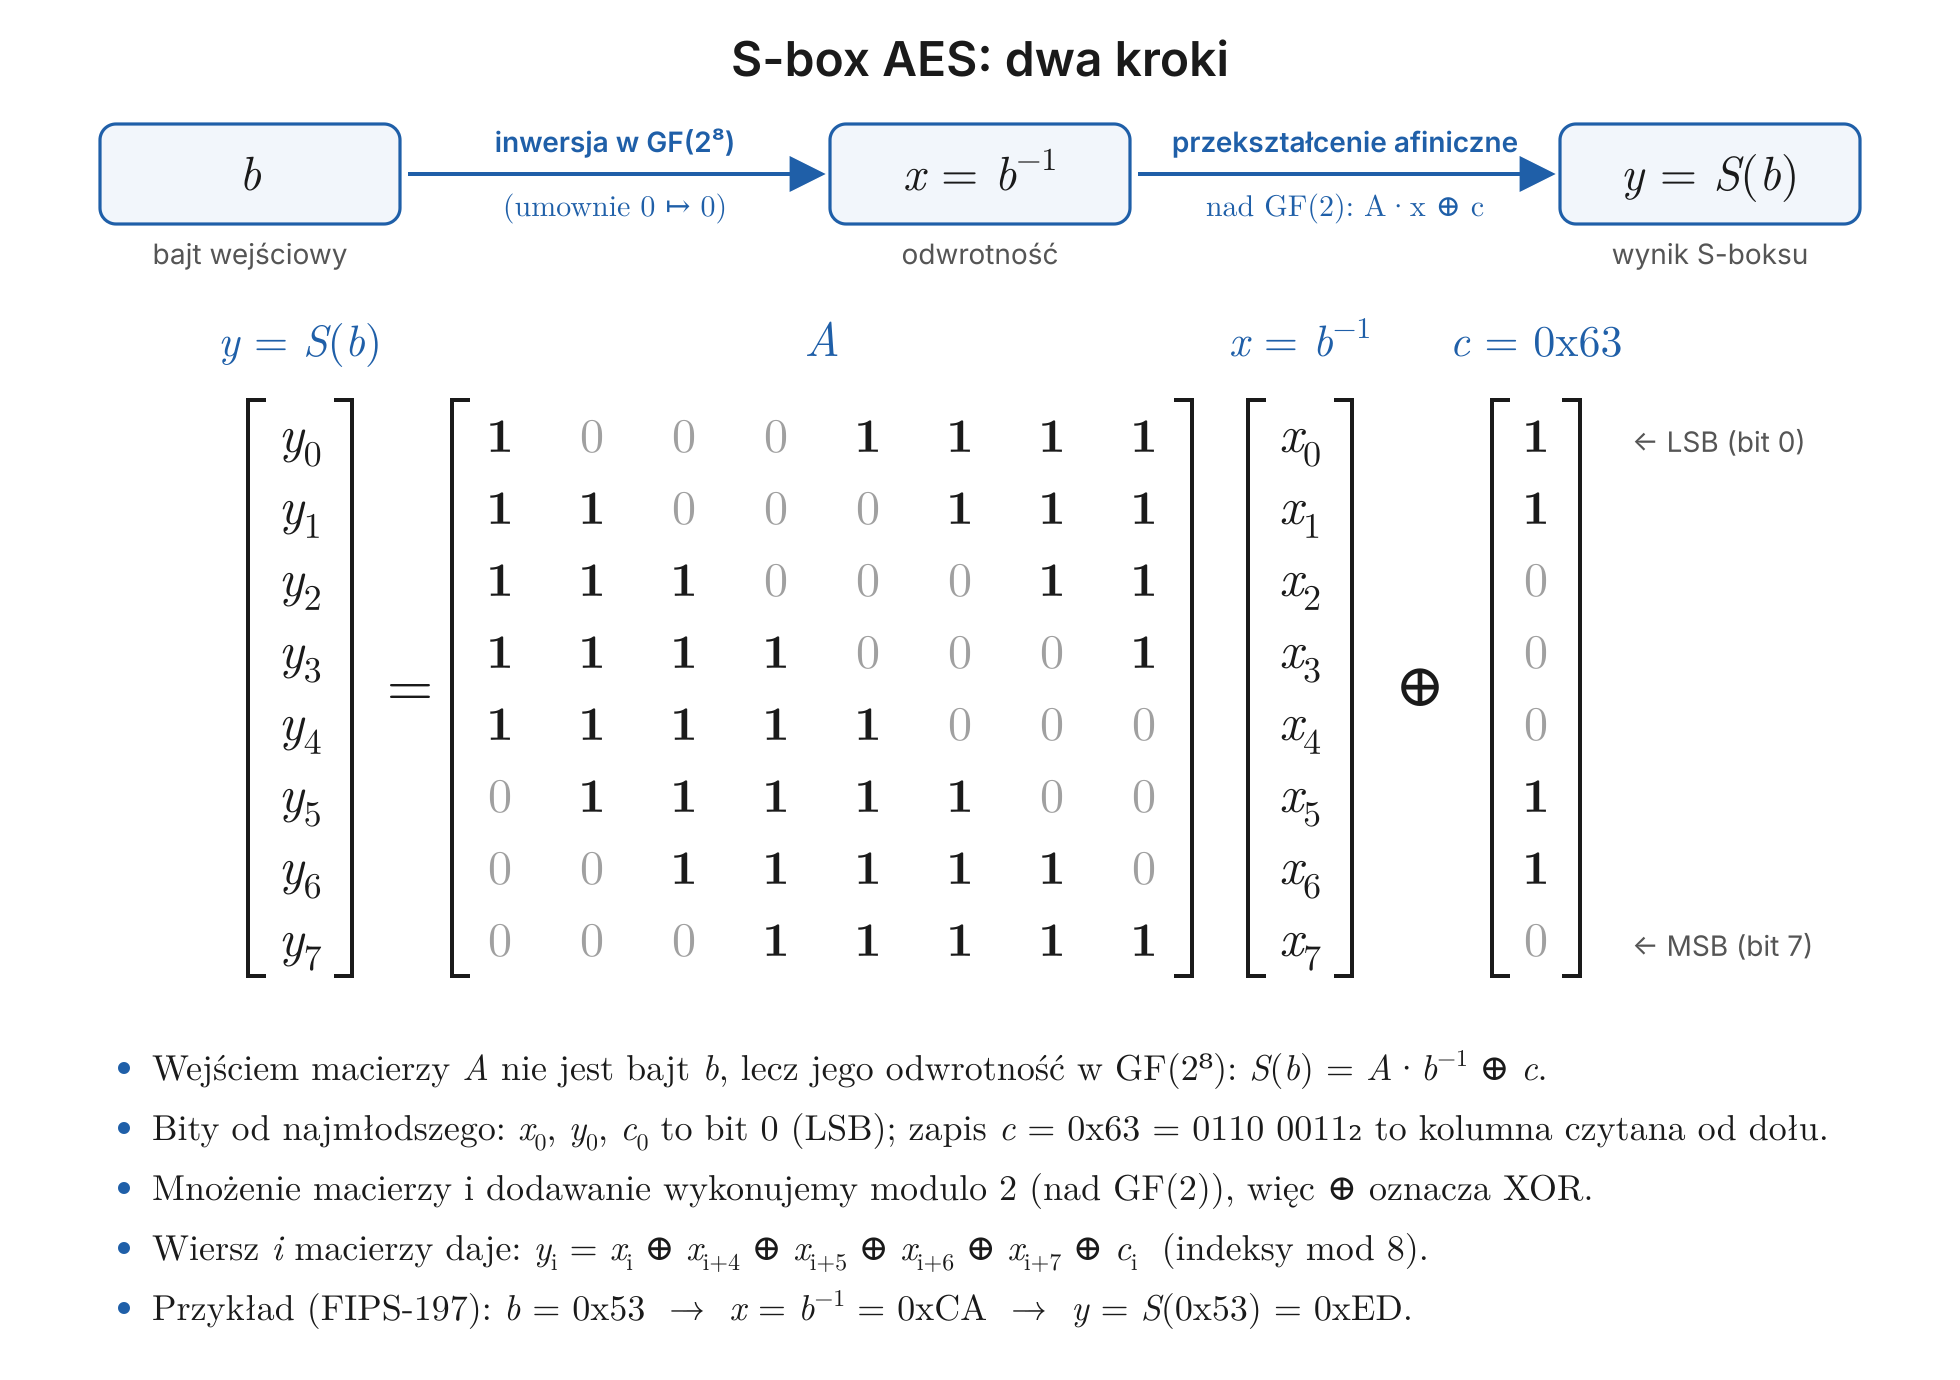

S-box AES powstaje przez wyznaczenie odwrotności multiplikatywnej w GF($2^8$), po którym następuje przekształcenie afiniczne nad GF(2) (ze stałą `0x63`). Kryteria projektowe (Daemen, Rijmen) to:
- mała maksymalna korelacja między liniowymi kombinacjami bitów wejścia i wyjścia (odporność na kryptoanalizę liniową),
- małe maksymalne prawdopodobieństwo propagacji różnic — jednorodność różnicowa równa 4 (odporność na kryptoanalizę różnicową),
- złożona postać algebraiczna oraz brak punktów stałych ($S(a) \ne a$) i przeciwnie stałych ($S(a) \ne \bar{a}$).

W kolejnej komórce podano funkcję `sbox(b)`, która oblicza **jedną** wartość S-boksu w dwóch krokach:
1. odwrotność $x = b^{-1}$ w GF($2^8$) — Twoja funkcja `gmul_inverse_tab` z Zadania 2,
2. przekształcenie afiniczne $y = A \cdot x \oplus$ `0x63`. Każdy wiersz macierzy $A$ jest cyklicznym przesunięciem poprzedniego, dlatego mnożenie przez $A$ można zapisać jako XOR bajtu $x$ z jego czterema obrotami w lewo: $y = x \oplus \mathrm{rotl}_1(x) \oplus \mathrm{rotl}_2(x) \oplus \mathrm{rotl}_3(x) \oplus \mathrm{rotl}_4(x) \oplus$ `0x63`.



In [ ]:
# obliczenie jednej wartości S-boksu: S(b) = A · b^-1 ⊕ 0x63
def sbox(b):
    x = gmul_inverse_tab(b)          # krok 1: odwrotność w GF(2^8) (umownie 0 → 0)
    y = x
    s = x
    for k in range(4):
        s = ((s << 1) % 256) | (s >> 7)   # obrót bajtu o 1 bit w lewo
        y = y ^ s                         # krok 2: y = x ⊕ rotl1(x) ⊕ … ⊕ rotl4(x)
    y = y ^ 0x63                     # … ⊕ 0x63
    return y

### Zadanie 3: wygeneruj tablice `SBOX` i `INV_SBOX`

Funkcja `sbox(b)` oblicza jedną wartość S-boksu, ale szyfr odczytuje S-box w każdej rundzie 16 razy, więc wygodniej (i szybciej) jest raz wygenerować całą tablicę. Tablice `SBOX` i `INV_SBOX` są potem używane przez funkcje `sub_word`, `sub_bytes` i `inv_sub_bytes`.

1. **`SBOX`** — lista 256 liczb, w której `SBOX[b] = sbox(b)` dla `b = 0, 1, …, 255`. Zacznij od pustej listy i w pętli dopisuj kolejne wartości (`append`).
2. **`INV_SBOX`** — S-box odwrotny: jeśli $S(b) = y$, to $S^{-1}(y) = b$. Utwórz listę 256 zer `INV_SBOX = [0] * 256`, a następnie dla każdego `b` od 0 do 255 wpisz `INV_SBOX[SBOX[b]] = b`.

**Sprawdzenie — złożenie.** `INV_SBOX` odwraca `SBOX`, więc złożenie obu tablic (w dowolnej kolejności) nie zmienia bajtu:

$$
S^{-1}(S(b)) = b \quad\text{oraz}\quad S(S^{-1}(y)) = y \qquad \text{dla każdego bajtu,}
$$

czyli w Pythonie `INV_SBOX[SBOX[b]] == b`. Komórka testowa sprawdza ten warunek dla wszystkich 256 bajtów. Warunek nie będzie spełniony, jeśli dwa różne bajty dają ten sam wynik $S(b)$, bo wtedy późniejszy wpis w `INV_SBOX` nadpisze wcześniejszy.

**Pytanie:** dlaczego S-box musi być permutacją? Co stałoby się z deszyfrowaniem, gdyby dwa różne bajty dawały ten sam wynik $S(b)$?


In [ ]:
# Zadanie 3: tablice SBOX i INV_SBOX
SBOX = []
# === TODO: dla b = 0, 1, …, 255 dopisz do SBOX wartość sbox(b) ===


INV_SBOX = [0] * 256
# === TODO: dla b = 0, 1, …, 255 wpisz INV_SBOX[SBOX[b]] = b ===



In [ ]:
# Testy Zadania 3: złożenie SBOX i INV_SBOX
bledy = 0
for b in range(256):
    if INV_SBOX[SBOX[b]] != b:
        bledy = bledy + 1
if bledy == 0:
    print("✅ INV_SBOX[SBOX[b]] == b dla każdego bajtu")
else:
    print("❌ INV_SBOX[SBOX[b]] != b dla", bledy, "bajtów")

# Opis algorytmu AES
#### Dane wejściowe: tekst jawny lub szyfrogram
AES jest szyfrem blokowym o rozmiarze bloku równym 128 bitów. Inaczej niż w przypadku DES, przetwarzanie w AES jest zorientowane bajtowo. Operujemy zatem na całych bajtach. Poniższa ilustracja przedstawia blok danych wejściowych. 

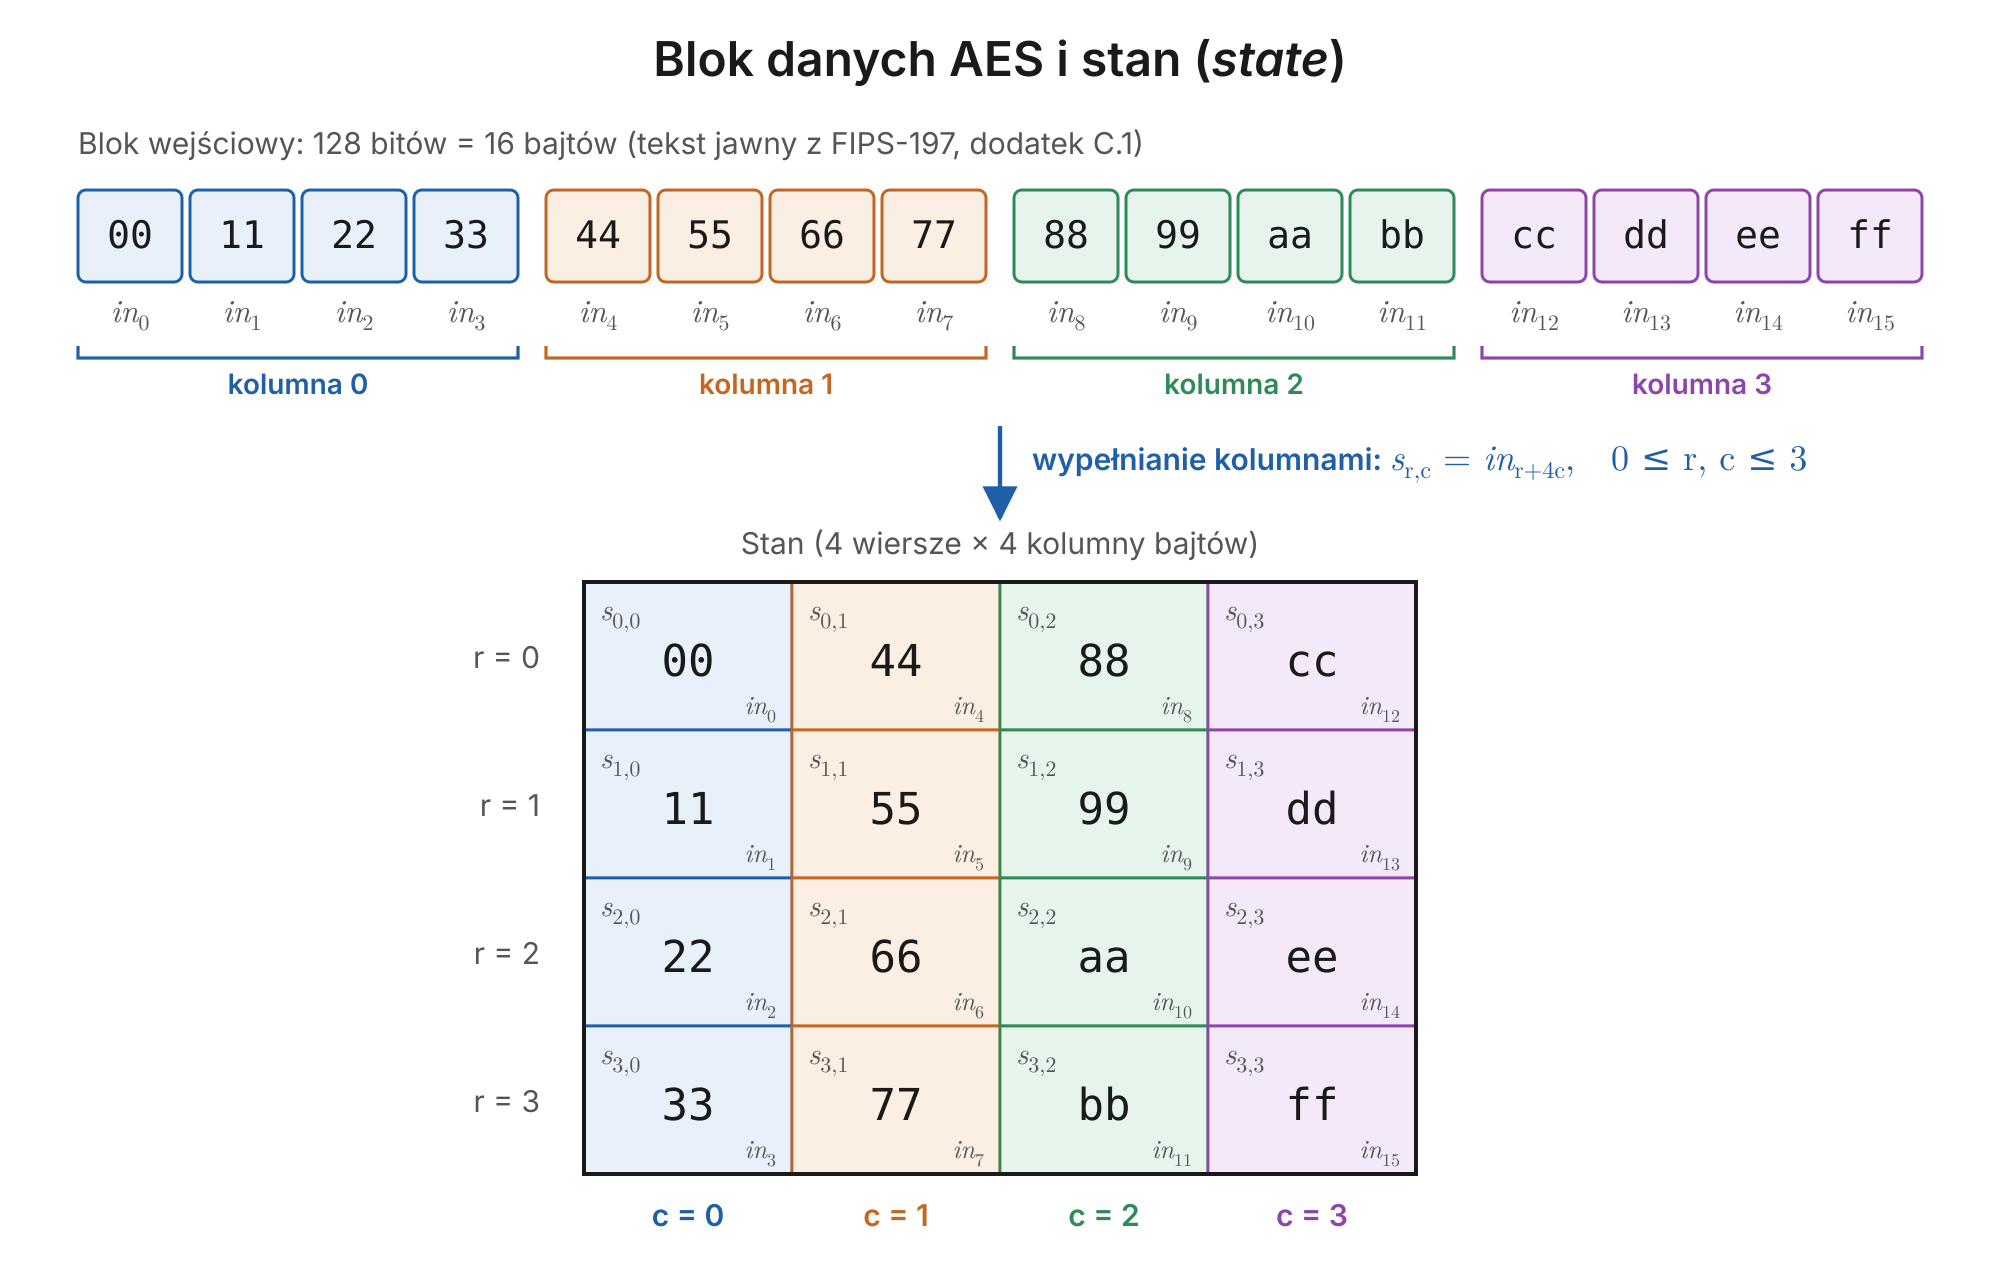

**Uwaga**: W trakcie pracy szyfru, zgodnie z opisem ze standardu FIPS-197, zmieniony jest blok danych zwany **stanem** (*state*). Dane wejściowe inicjują stan, a na końcu szyfrowania (deszyfrowania) stan kopiowany jest jako blok wyjściowy.  

1. **Faza zarządzania kluczem**: Rozszerzenie klucza ze 128 bitów do 176 bajtów. Rozszerzony klucz, nazywany też poniżej „*key schedule*”, możemy traktować jako tablicę 11×16 bajtów, której wiersze używamy jako kluczy rund (każdy wiersz, czyli 16 bajtów, tworzy klucz kolejnej rundy).
2. **Faza szyfrowania**
    1. `AddRoundKey` (XOR stanu z kluczem rundy). Stan tworzymy, przekształcając 16-bajtowy tekst jawny w tablicę 4×4 (bajty wypełniają ją kolumnami), a kluczem rundy w tej operacji jest pierwszy wiersz key schedule, czyli pierwotny klucz.
    2. Dla AES o kluczu 128 bitów wykonujemy 9 rund:
        1. `SubBytes` - każdy bajt stanu jest zastępowany innym, korzystając z tablicy SBOX. Działanie ma zapewnić nieliniowość (więcej na temat mechanizmu w opisie S-boksów).
        1. `ShiftRows` - wiersz $r$ stanu ($r = 0,\dots,3$) jest cyklicznie przesuwany w lewo o $r$ pozycji. Dzięki temu bajty jednej kolumny trafiają do różnych kolumn, więc kolumny **nie** są szyfrowane niezależnie (dyfuzja między kolumnami). Bez ShiftRows AES rozpadłby się na cztery niezależne szyfry 32-bitowe; razem z MixColumns już po dwóch rundach każdy bajt stanu zależy od każdego bajtu wejścia.
        3. `MixColumns` - każda kolumna jest mnożona (w ciele GF($2^8$)) przez stałą macierz, a zamiast dodawania używamy operacji XOR, np. dla pierwszego bajtu kolumny gmul(a[0], 2) ^ gmul(a[1], 3) ^ gmul(a[2], 1) ^ gmul(a[3], 1) (patrz opis poniżej).
        4. `AddRoundKey` - stan = XOR stanu z kluczem rundy.
    3. Finalna runda (dziesiąta):
        1. `SubBytes`
        2. `ShiftRows`
        3. `AddRoundKey` - kluczem rundy jest ostatni wiersz key schedule (w ten sposób został użyty cały rozszerzony klucz).

    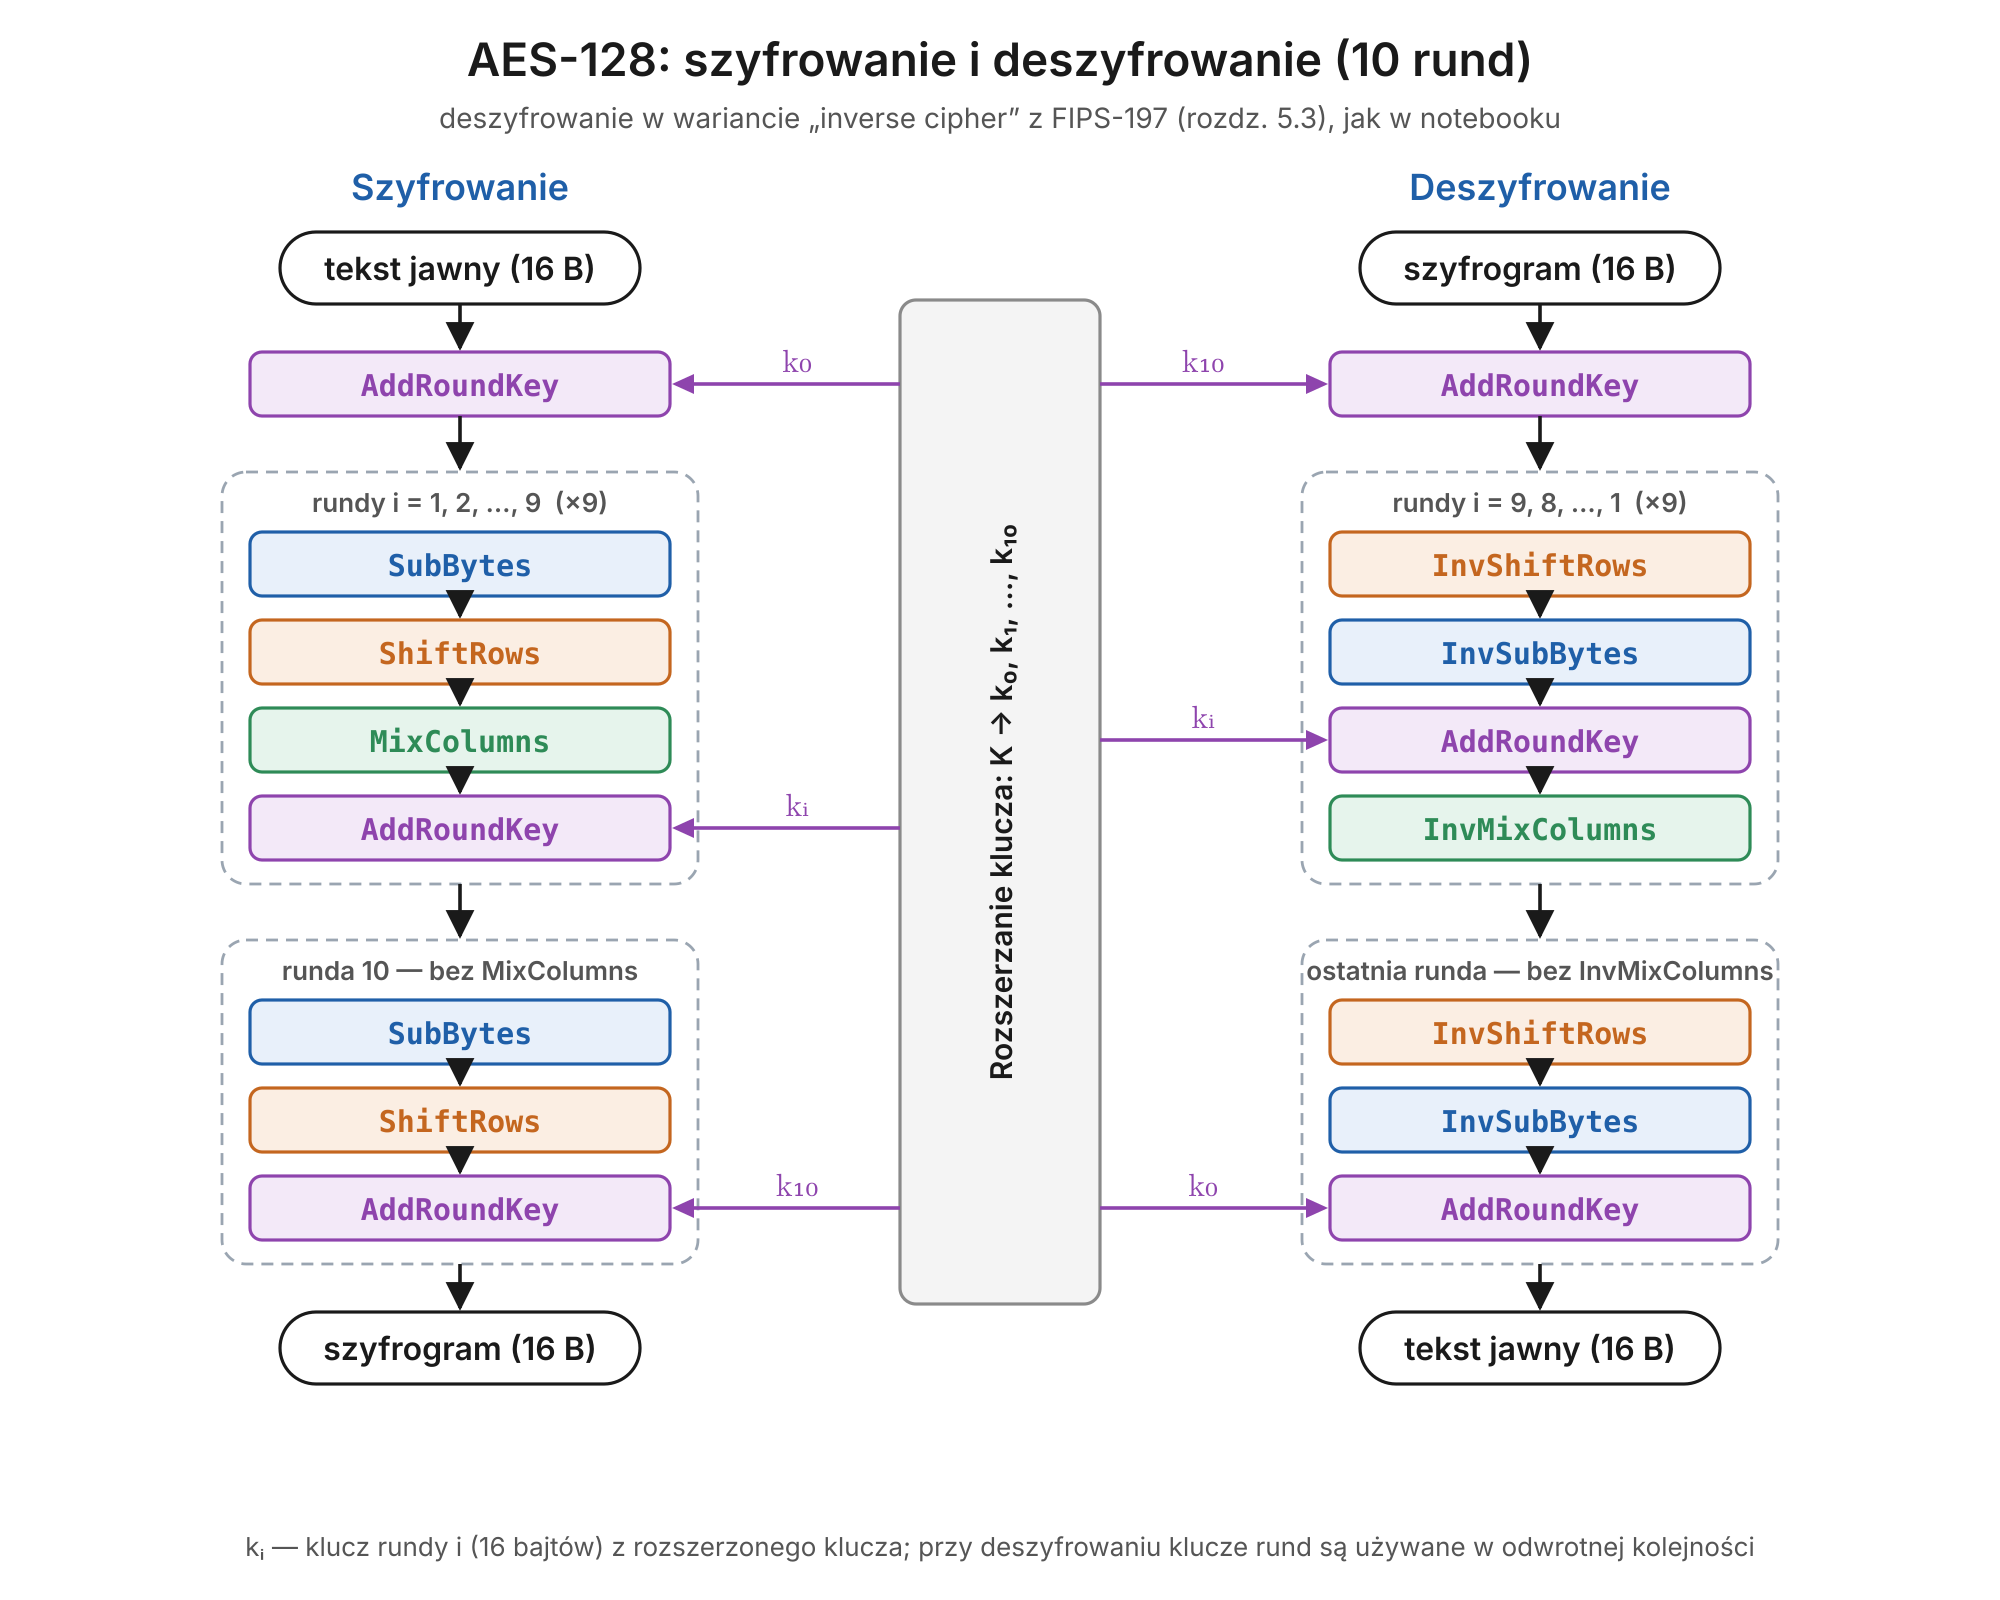

##  Rozszerzanie klucza (*key schedule*)
Pierwszym krokiem w implementacji AES o rozmiarze klucza 128 bitów jest wygenerowanie z klucza głównego 11 128-bitowych podkluczy (kluczy rund).

1. Klucz główny K tworzy pierwsze cztery 4-bajtowe słowa (kolumny) $w_0, w_1, w_2, w_3$.
2. Kolejne słowa $w_i$ dla $i = 4, \dots, 43$ wyznaczamy następująco:

    a) pierwsza kolumna każdego podklucza ($i$ podzielne przez 4): $w_i = w_{i-4} \oplus \mathrm{SubWord}(\mathrm{RotWord}(w_{i-1})) \oplus \mathrm{Rcon}_{i/4}$ — przekształceniu podlega kolumna **poprzednia** ($i-1$), a wynik jest XOR-owany z kolumną $i-4$;

    b) pozostałe kolumny: $w_i = w_{i-4} \oplus w_{i-1}$.

RotWord to cykliczne przesunięcie bajtów słowa o jedną pozycję w lewo, a SubWord — zastosowanie S-boksu do każdego z 4 bajtów słowa.



## Zarządzanie kluczem w całości


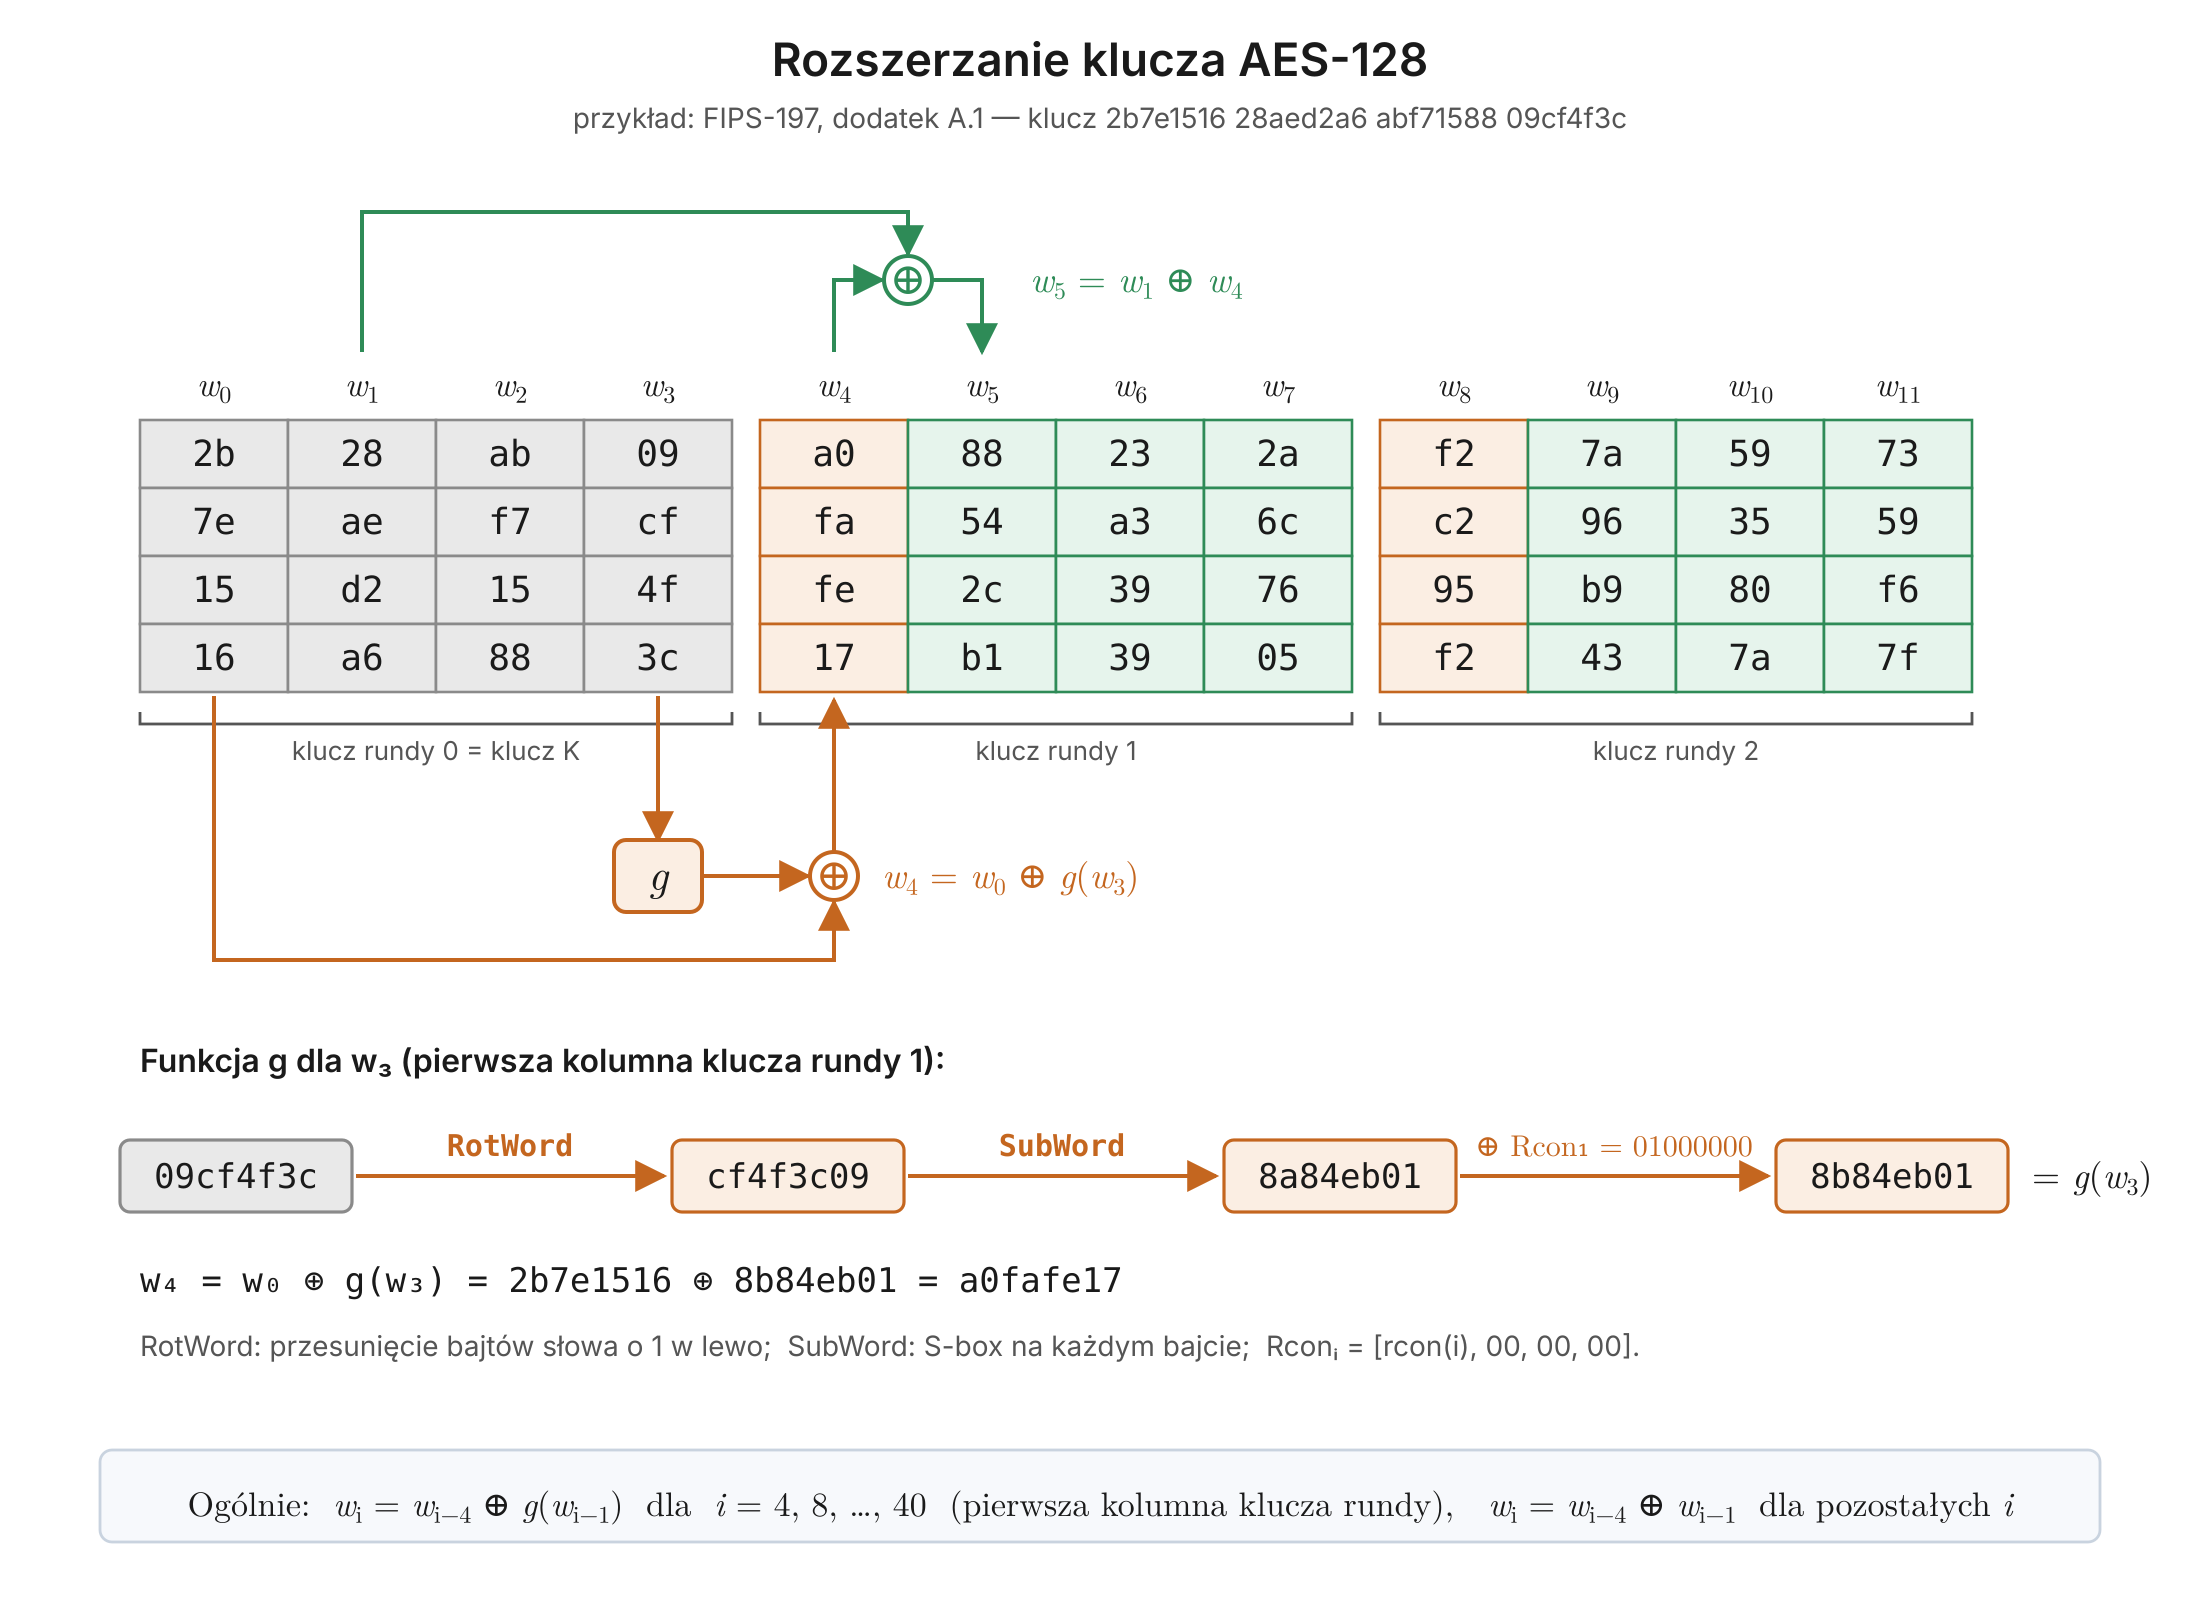

### Stałe rundy Rcon 

Dodanie stałej rundy Rcon(i) ma na celu między innymi eliminację potencjalnych słabych kluczy. Tablica stałych Rcon ma postać $[rc_i, 0x00, 0x00, 0x00 ]$ gdzie $rc_i$ jest odpowiednim wielomianem z ciała $GF(2^8)$. 

In [ ]:
#Rc - stała rundy (round constant)
def rcon(i):
    if i < 1:
        raise ValueError("rcon: numer rundy i musi być >= 1")
    c = 1
    if i == 1:
        return 1
    while i != 1:
        b = c * 2
    
        if c >= 0x80:
            b = b ^ 0x1B
            b = b % 256
        c = b
        i = i-1
    return b

val = rcon(10)    
print("Dec:", val, "hex:", hex(val))  

In [ ]:
def rot_word(word):
    """ RotWord: cykliczne przesunięcie 4 bajtów słowa o jedną pozycję w lewo. """
    return [word[1], word[2], word[3], word[0]]

def sub_word(word):
    """ SubWord: S-box zastosowany do każdego z 4 bajtów słowa. """
    result = []
    for b in word:
        result.append(SBOX[b])
    return result

def schedule_core(word, i):
    """ Przekształcenie pierwszej kolumny klucza rundy: SubWord(RotWord(w)) ⊕ [rcon(i), 0, 0, 0]. """
    word = rot_word(word)
    word = sub_word(word)
    word[0] = word[0] ^ rcon(i)
    return word

print(bytes_to_hex(rot_word([0x00, 0xff, 0x7f, 0x55])))         # ff7f5500
print(bytes_to_hex(schedule_core([0x00, 0xff, 0x7f, 0x55], 2)))  # SubWord(ff7f5500) ⊕ 02000000

In [ ]:
def expand_key(key):
    """ Rozszerzanie klucza AES-128: klucz 16 bajtów → 176 bajtów (11 kluczy rund po 16 bajtów). """
    expanded_key = []
    for b in key:
        expanded_key.append(b)          # pierwsze 16 bajtów to klucz główny (słowa w0…w3)

    n = 1                               # numer stałej rundy rcon
    while len(expanded_key) < 176:
        # ostatnie słowo (4 bajty) rozszerzonego klucza: w(i-1)
        last_word = []
        for k in range(4):
            last_word.append(expanded_key[len(expanded_key) - 4 + k])

        # pierwsza kolumna każdego klucza rundy: przekształcamy w(i-1)
        if len(expanded_key) % 16 == 0:
            last_word = schedule_core(last_word, n)
            n = n + 1

        # w(i) = w(i-4) XOR przekształcone (lub nie) w(i-1); bajt po bajcie
        for k in range(4):
            expanded_key.append(expanded_key[len(expanded_key) - 16] ^ last_word[k])
    return expanded_key

def get_round_keys(key_schedule, i):
    """ Klucz rundy i (i = 0…10) — 16 kolejnych bajtów rozszerzonego klucza. """
    return key_schedule[16 * i : 16 * (i + 1)]

test_key = hex_to_bytes("000102030405060708090a0b0c0d0e0f")
key_table = expand_key(test_key)
for i in range(11):   # 11 kluczy rund: 0…10
    print("klucz rundy", i, ":", bytes_to_hex(get_round_keys(key_table, i)))

# sprawdzenie z FIPS-197, dodatek A.1: ostatnie słowo rozszerzonego klucza = b6630ca6
fips_a1 = expand_key(hex_to_bytes("2b7e151628aed2a6abf7158809cf4f3c"))
print("FIPS-197 A.1, ostatnie słowo:", bytes_to_hex(fips_a1[172:176]), "(oczekiwane: b6630ca6)")

#### AddRoundKey

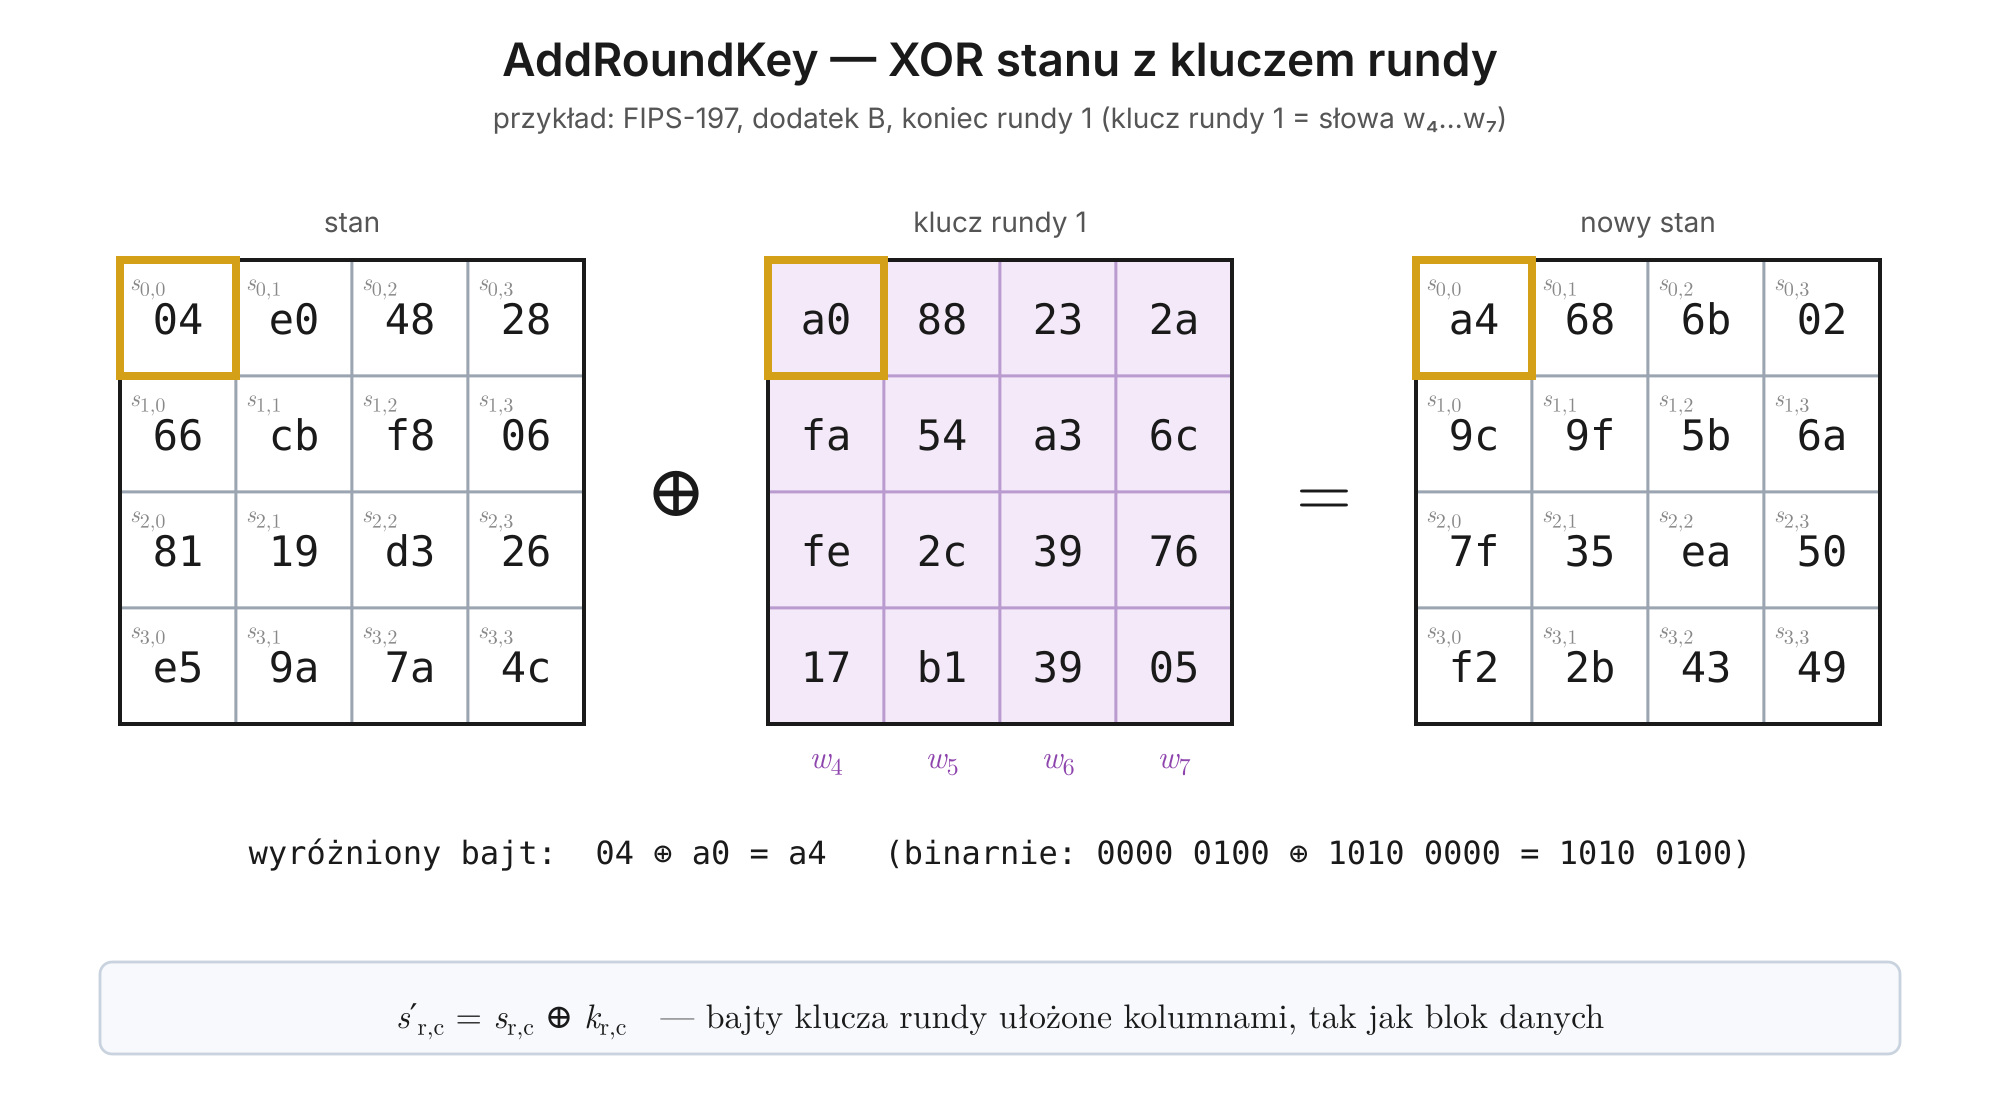

In [ ]:
#dodawanie klucza rundy
def add_round_key(state, round_key):
    # round_key to lista 16 bajtów klucza rundy, ułożonych tak jak blok danych:
    # bajt numer r + 4c trafia do wiersza r i kolumny c
    for r in range(4):
        for c in range(4):
            state[r][c] = state[r][c] ^ round_key[r + 4 * c]

#### SubBytes
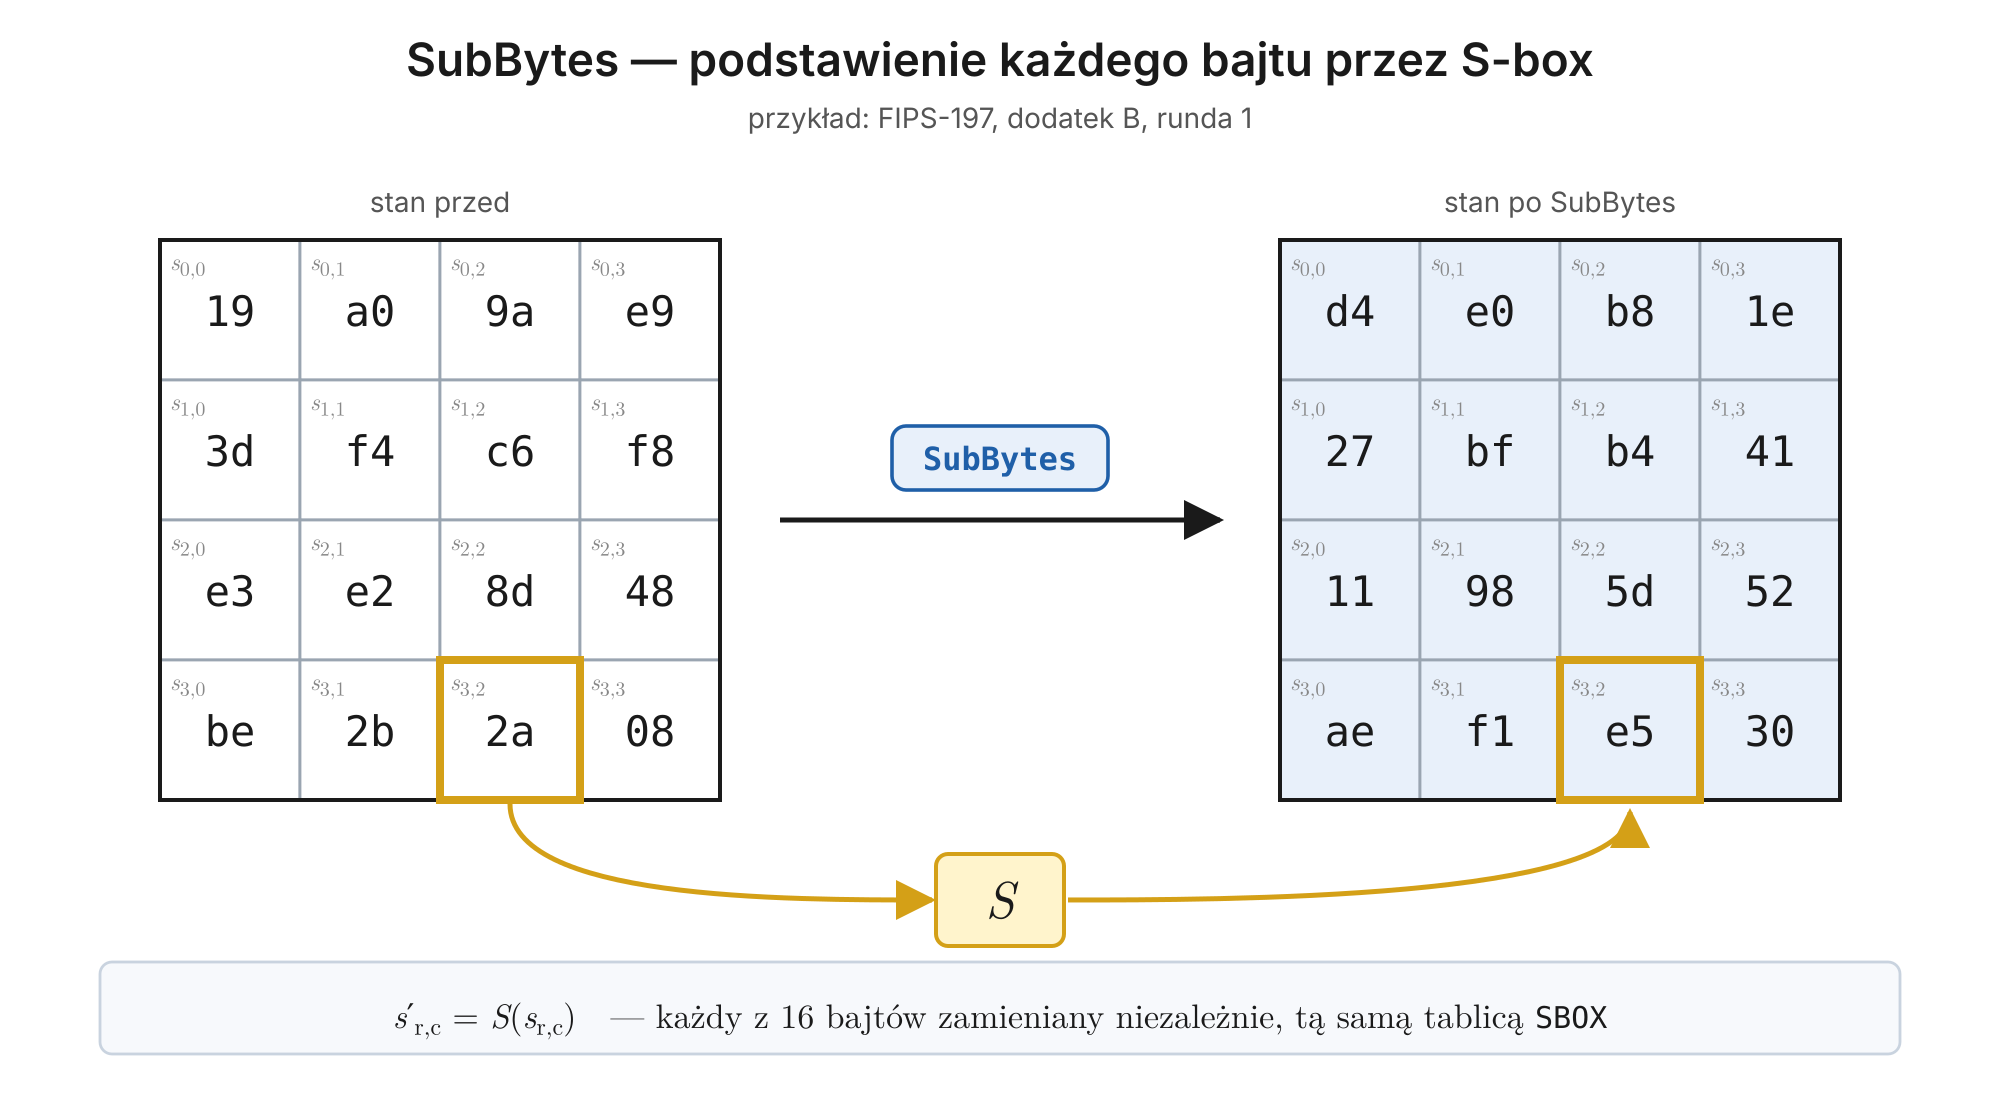

In [ ]:
#aplikacja S-boxów
def sub_bytes(state):
    # każdy bajt stanu zastępujemy wartością z tablicy SBOX
    for r in range(4):
        for c in range(4):
            state[r][c] = SBOX[state[r][c]]

#odwrócenie aplikacji S-boxów
def inv_sub_bytes(state):
    for r in range(4):
        for c in range(4):
            state[r][c] = INV_SBOX[state[r][c]]

#### ShiftRows
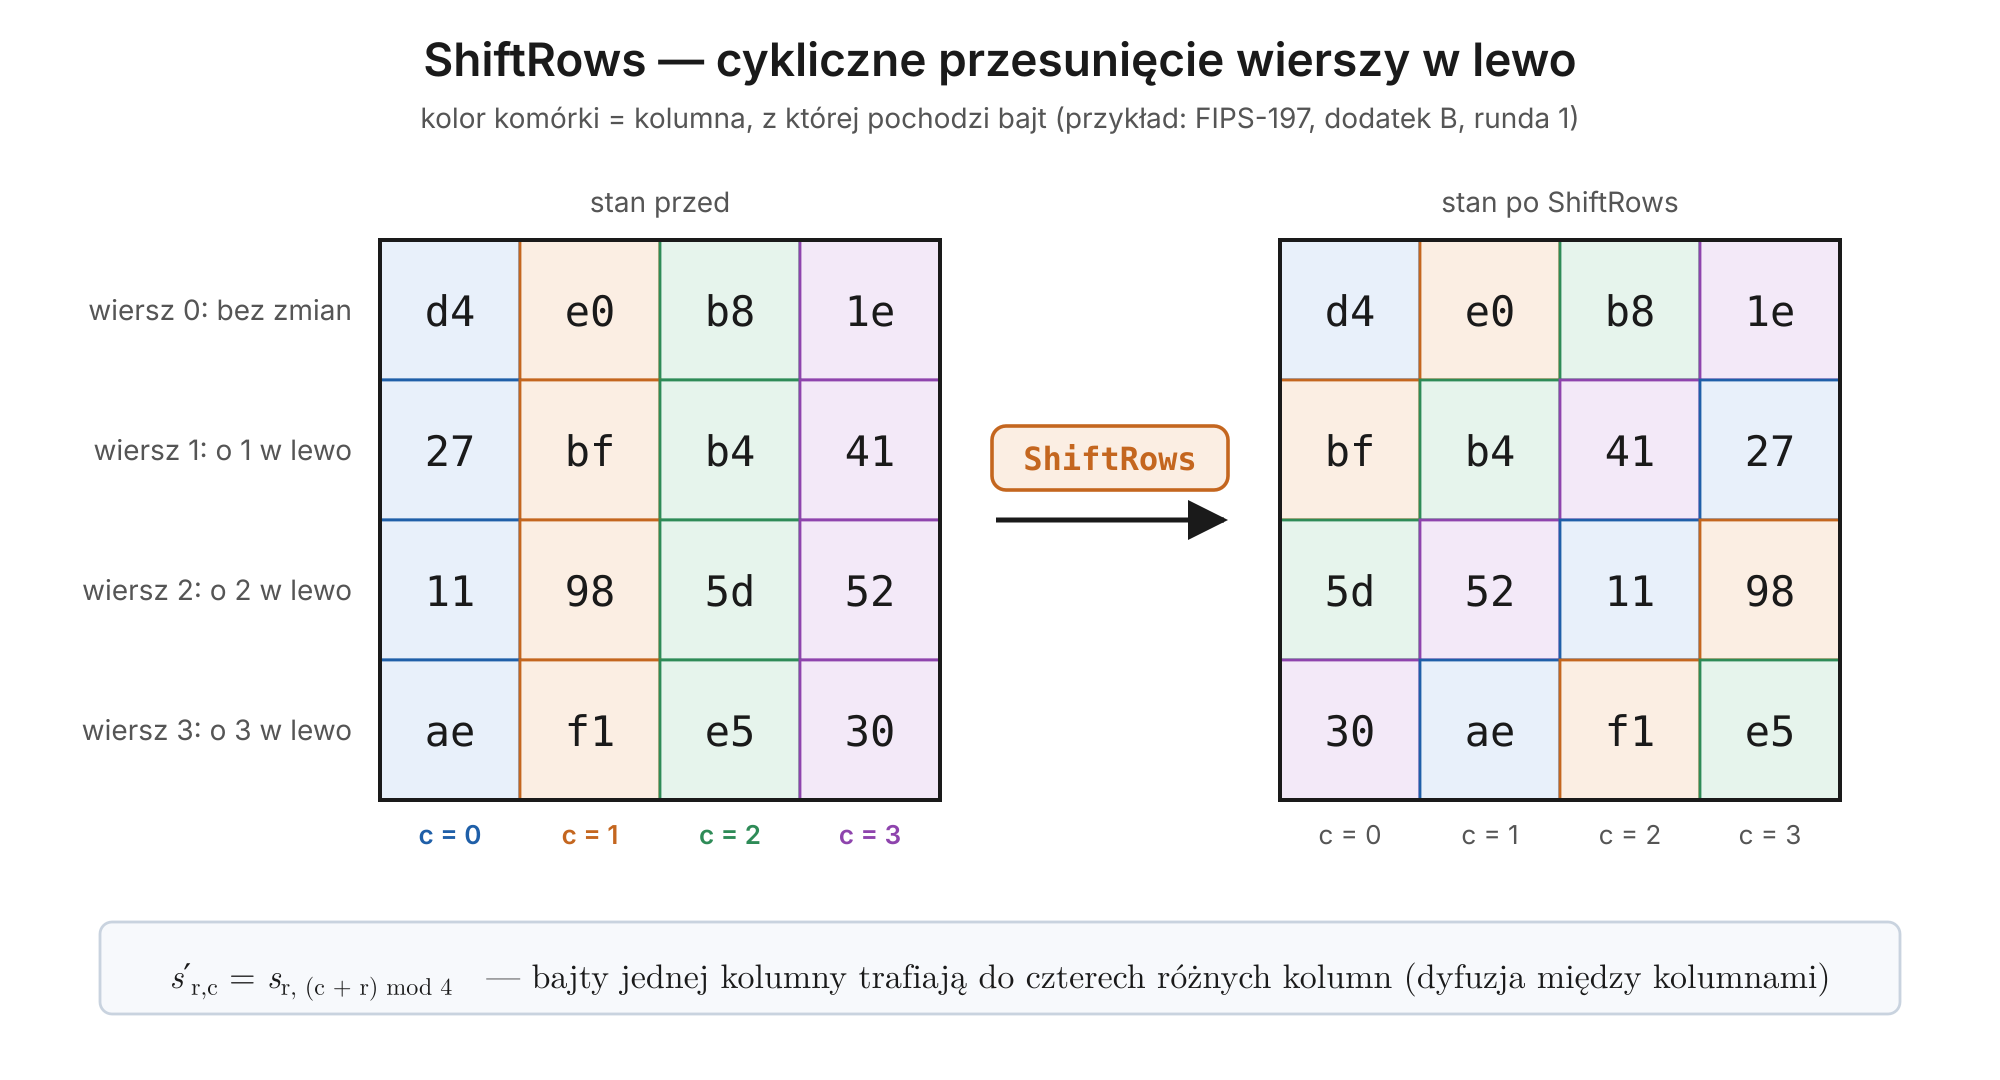

In [ ]:
def shift_rows(state):
    # wiersz r przesuwamy cyklicznie o r pozycji w lewo (wiersz 0 zostaje bez zmian):
    # nowy bajt w kolumnie c to stary bajt z kolumny (c + r) mod 4
    for r in range(1, 4):
        old_row = state[r]
        new_row = []
        for c in range(4):
            new_row.append(old_row[(c + r) % 4])
        state[r] = new_row


def inv_shift_rows(state):
    # operacja odwrotna: wiersz r przesuwamy cyklicznie o r pozycji w prawo
    for r in range(1, 4):
        old_row = state[r]
        new_row = []
        for c in range(4):
            new_row.append(old_row[(c - r + 4) % 4])
        state[r] = new_row

#### MixColumns
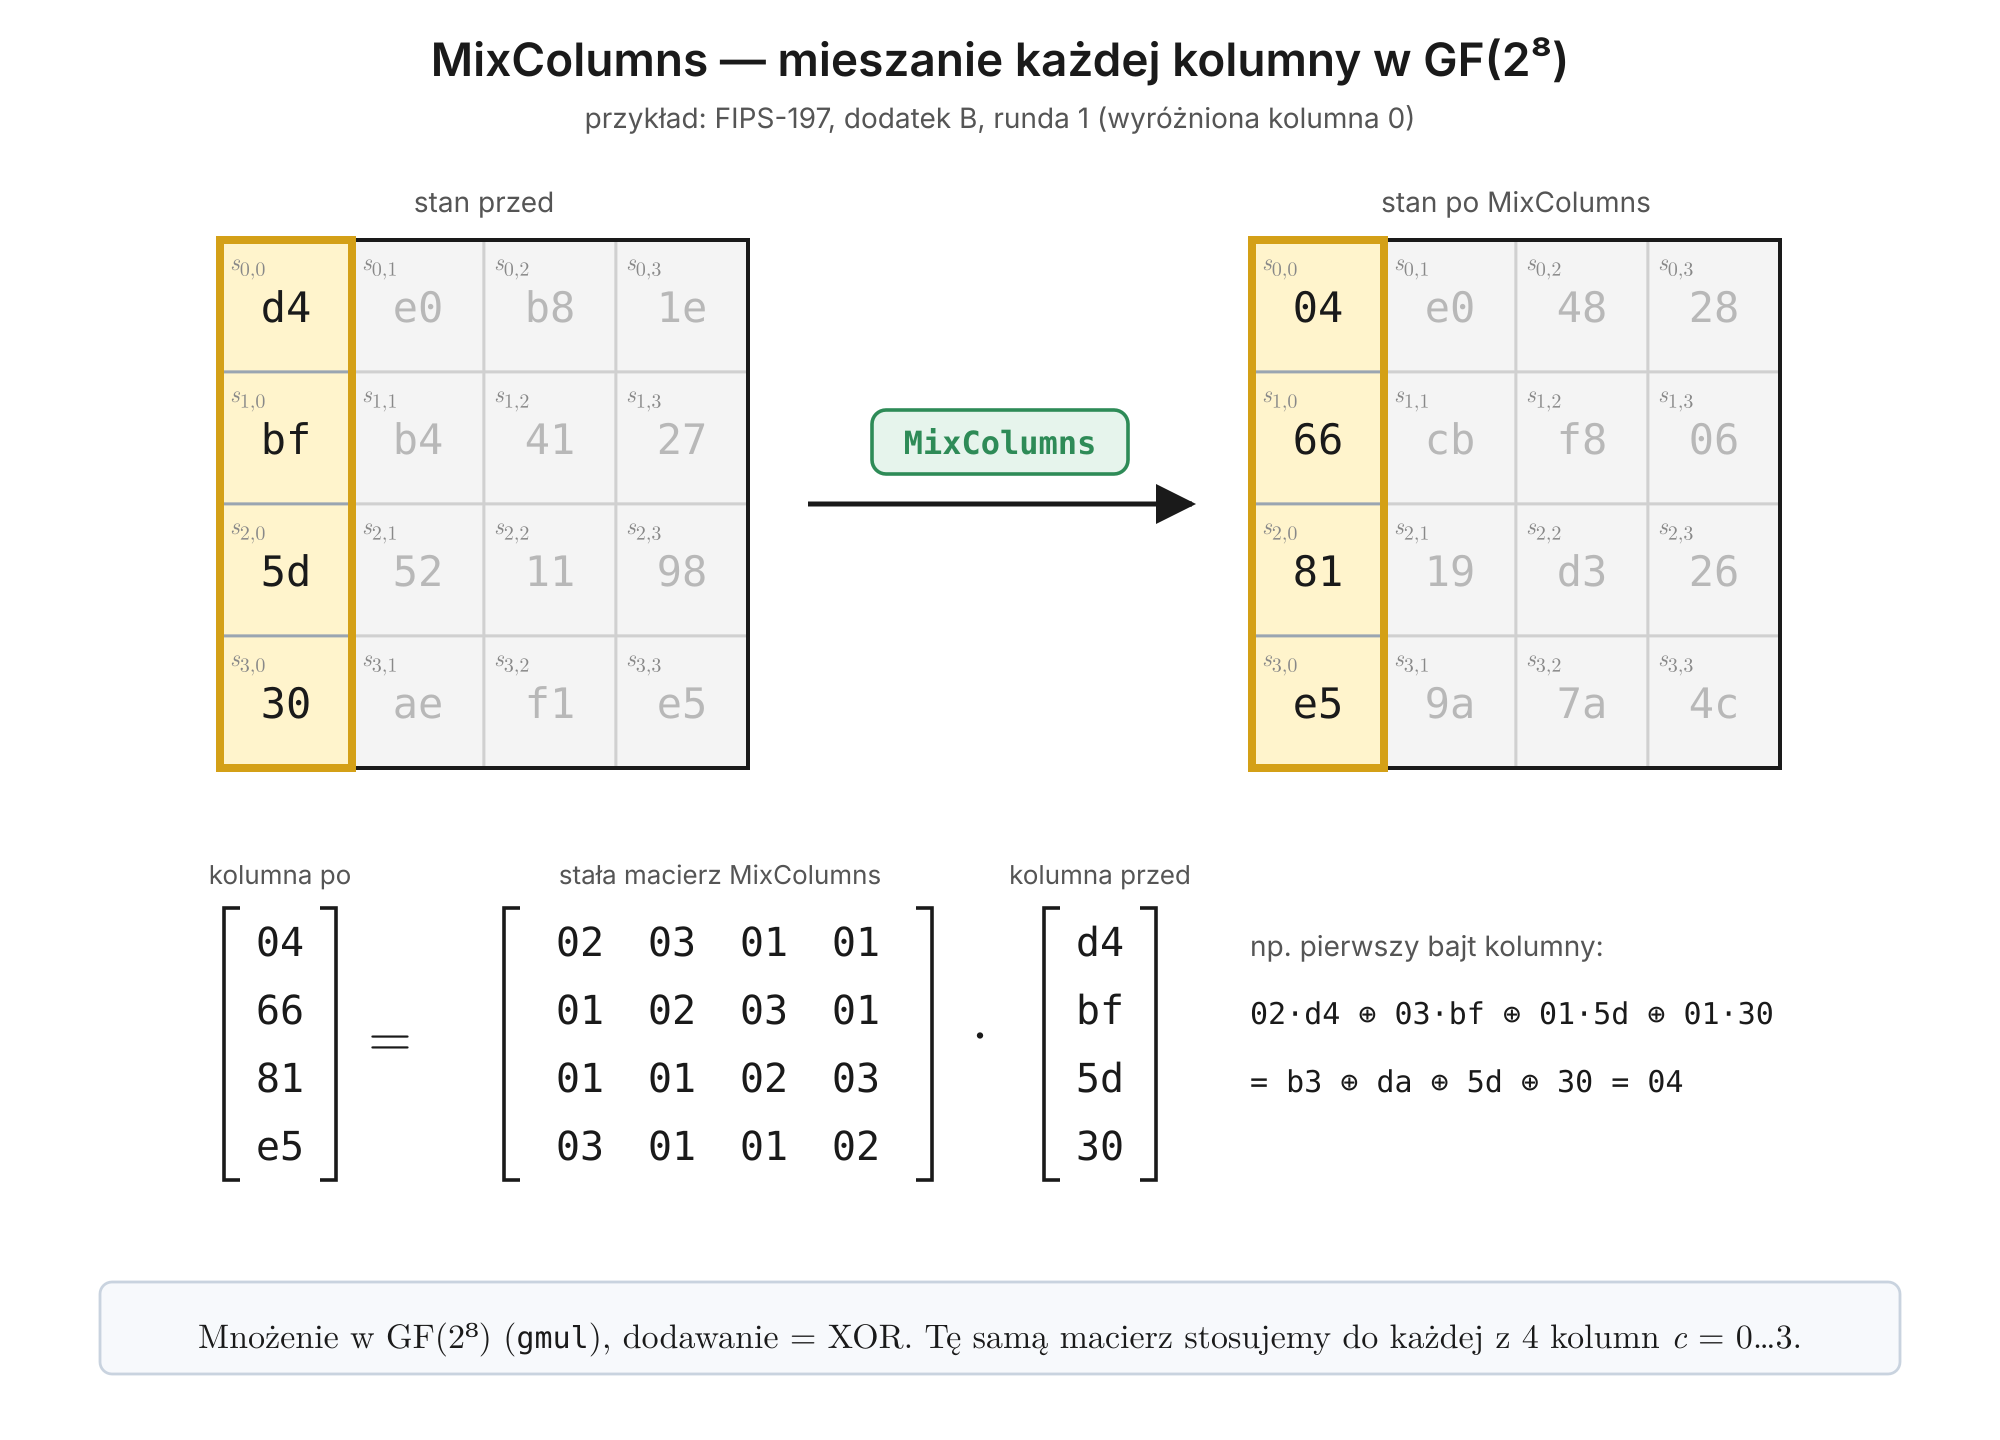

In [ ]:
def mix_one_column(column):
    """ Miesza jedną kolumnę stanu (listę 4 bajtów). Funkcja zmienia przekazaną listę. """
    a = [column[0], column[1], column[2], column[3]]    # kopia wartości przed zmianą

    # mnożenie kolumny przez macierz MixColumns w GF(2^8); zamiast dodawania używamy XOR
    column[0] = gmul(a[0], 2) ^ gmul(a[1], 3) ^ gmul(a[2], 1) ^ gmul(a[3], 1)
    column[1] = gmul(a[0], 1) ^ gmul(a[1], 2) ^ gmul(a[2], 3) ^ gmul(a[3], 1)
    column[2] = gmul(a[0], 1) ^ gmul(a[1], 1) ^ gmul(a[2], 2) ^ gmul(a[3], 3)
    column[3] = gmul(a[0], 3) ^ gmul(a[1], 1) ^ gmul(a[2], 1) ^ gmul(a[3], 2)


def mix_columns(state):
    # MixColumns działa na KOLUMNACH: kolumna c to state[0][c], state[1][c], state[2][c], state[3][c]
    for c in range(4):
        column = []
        for r in range(4):
            column.append(state[r][c])     # 1. wyjmujemy kolumnę ze stanu
        mix_one_column(column)             # 2. mieszamy ją
        for r in range(4):
            state[r][c] = column[r]        # 3. wkładamy wynik z powrotem do stanu


def inv_mix_one_column(column):
    a = [column[0], column[1], column[2], column[3]]

    # mnożenie przez macierz odwrotną (współczynniki 14, 11, 13, 9)
    column[0] = gmul(a[0], 14) ^ gmul(a[1], 11) ^ gmul(a[2], 13) ^ gmul(a[3], 9)
    column[1] = gmul(a[0], 9) ^ gmul(a[1], 14) ^ gmul(a[2], 11) ^ gmul(a[3], 13)
    column[2] = gmul(a[0], 13) ^ gmul(a[1], 9) ^ gmul(a[2], 14) ^ gmul(a[3], 11)
    column[3] = gmul(a[0], 11) ^ gmul(a[1], 13) ^ gmul(a[2], 9) ^ gmul(a[3], 14)


def inv_mix_columns(state):
    for c in range(4):
        column = []
        for r in range(4):
            column.append(state[r][c])
        inv_mix_one_column(column)
        for r in range(4):
            state[r][c] = column[r]

# przykład z FIPS-197 (dodatek B, runda 1, stan po ShiftRows):
# kolumna 0 to d4 bf 5d 30, a po MixColumns powinna być równa 04 66 81 e5
#state = [[0xd4, 0xe0, 0xb8, 0x1e],
#         [0xbf, 0xb4, 0x41, 0x27],
#         [0x5d, 0x52, 0x11, 0x98],
#         [0x30, 0xae, 0xf1, 0xe5]]
#mix_columns(state)
#print_state(state)          # kolumna 0: 04 66 81 e5
#inv_mix_columns(state)
#print_state(state)          # z powrotem stan wejściowy

## Szyfrujmy AESem!

### Zadanie 4: szyfrowanie i deszyfrowanie bloku
Uzupełnij funkcje `aes128_encrypt` i `aes128_decrypt` (rundy 1–9 oraz rundę ostatnią), korzystając z funkcji zdefiniowanych powyżej.

Poprawność implementacji sprawdź wektorem testowym z FIPS-197 (dodatek C.1) — służy do tego komórka testowa poniżej:
- klucz: `000102030405060708090a0b0c0d0e0f`
- tekst jawny: `00112233445566778899aabbccddeeff`
- oczekiwany szyfrogram: `69c4e0d86a7b0430d8cdb78070b4c55a`

**Uwaga:** to, że odszyfrowanie zwraca tekst jawny, nie dowodzi jeszcze zgodności implementacji ze standardem.

In [ ]:
#szyfrowanie pojedynczego bloku 16 bajtowego
def aes128_encrypt(plaintext_block, key):

    # === TODO uzupełnij implementacje =====
    #wygenerujmy klucze rund

    # 4x4 grid 
    state = bytes_to_matrix(plaintext_block)
    
    
    for i in range(1,10):
        #9 rund szyfrowania
        pass   # === TODO === usuń „pass” po uzupełnieniu pętli

    #i jeszcze ostatnie "wybrakowania" runda

    return state

#deszyfrowanie pojedynczego bloku 
def aes128_decrypt(ciphertext_block, key):
    # === TODO uzupełnij implementacje =====
    
   
    state = bytes_to_matrix(ciphertext_block)
   
    
    for i in range(9, 0, -1):
        # === TODO === (deszyfrowania)
        pass   # === TODO === usuń „pass” po uzupełnieniu pętli
      

    ## i znowu ostatnia runda
    
    return state

def AES_encrypt(plaintext_block, key):
    """ Szyfruje blok 16 bajtów kluczem 16 bajtów; zwraca blok 16 bajtów. """
    state = aes128_encrypt(plaintext_block, key)
    return matrix_to_bytes(state)

def AES_decrypt(ciphertext_block, key):
    """ Deszyfruje blok 16 bajtów kluczem 16 bajtów; zwraca blok 16 bajtów. """
    state = aes128_decrypt(ciphertext_block, key)
    return matrix_to_bytes(state)

# blok 16 bajtów (128 bitów)
plaintext = hex_to_bytes("00000000001234324015451543513451")
# klucz 16 bajtów (128 bitów)
key = hex_to_bytes("0007f88ff88ff88ff8ff11ff11ff11ff")

print("Tekst jawny:        ", bytes_to_hex(plaintext))
encrypted_message = AES_encrypt(plaintext, key)
print("Szyfrogram:         ", bytes_to_hex(encrypted_message))
decrypted_message = AES_decrypt(encrypted_message, key)
print("Tekst odszyfrowany: ", bytes_to_hex(decrypted_message))

In [ ]:
# Test Zadania 4: wektor testowy FIPS-197, dodatek C.1
fips_key = hex_to_bytes("000102030405060708090a0b0c0d0e0f")
fips_plaintext = hex_to_bytes("00112233445566778899aabbccddeeff")
fips_expected = "69c4e0d86a7b0430d8cdb78070b4c55a"

wynik = bytes_to_hex(AES_encrypt(fips_plaintext, fips_key))
print("otrzymano: ", wynik)
print("oczekiwano:", fips_expected)
if wynik == fips_expected:
    print("✅ szyfrowanie zgodne z FIPS-197")
else:
    print("❌ szyfrowanie niezgodne z FIPS-197")

if AES_decrypt(hex_to_bytes(fips_expected), fips_key) == fips_plaintext:
    print("✅ deszyfrowanie zwraca tekst jawny z FIPS-197")
else:
    print("❌ deszyfrowanie nie zwraca tekstu jawnego z FIPS-197")


# Część II: Tryby algorytmów szyfrowych 
Stosowanie szyfrów blokowych wymaga rozwiązania dwóch problemów:
1. Co zrobić gdy wiadomość jest większa niż rozmiar bloku (przypomnienie: AES ma blok o rozmiarze 128 bitów)
2. Co zrobić gdy rozmiar wiadomości nie jest wielokrotnością rozmiaru bloków

Ad 1) Rozwiązaniem jest zastosowanie tzw. trybów algorytmów szyfrowych (*block cipher mode of operation*) czyli sposób szyfrowania wiadomości podzielonej na bloki. 
Ad 2) Rozwiązaniem jest zastosowanie dopełnienia (*padding*) czyli porcji danych dodanych do ostatniego bloku w celu dopełnienia go do pełnej wielkości bloku


### Zadanie 5: tryby ECB, CBC i CTR
Zapoznaj się z trybami ECB, CBC i CTR. Zaimplementuj je dla powyższej implementacji AES. 

### Tryb ECB 
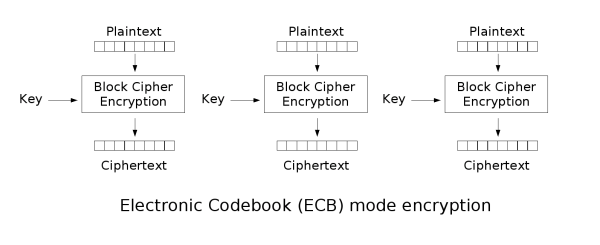


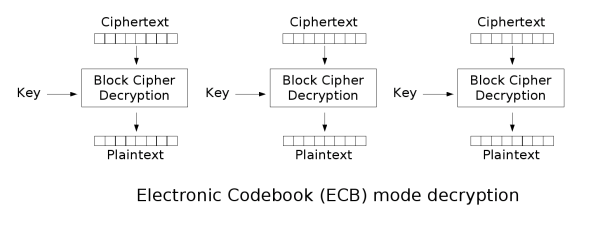

### Tryb CBC
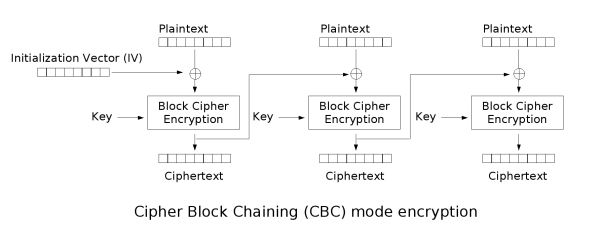

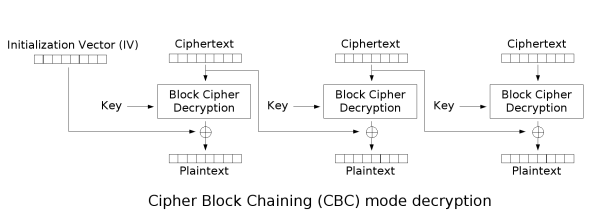

### Tryb CTR
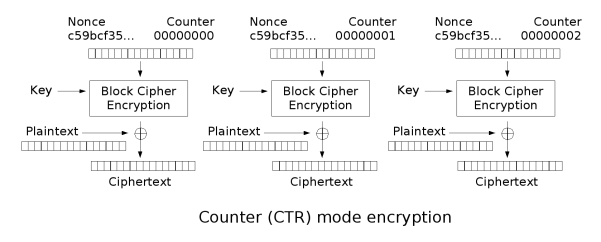

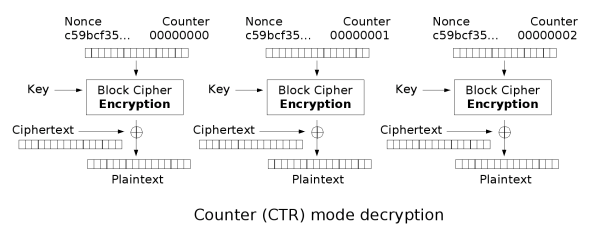

In [ ]:
# Funkcje pomocnicze dla trybów

def xor_blocks(a, b):
    """ XOR dwóch list bajtów; wynik ma długość krótszej z nich (przydatne dla ostatniego bloku w CTR). """
    n = min(len(a), len(b))
    result = []
    for i in range(n):
        result.append(a[i] ^ b[i])
    return result

def int_to_bytes(number, length):
    """ Liczba całkowita → lista `length` bajtów (najstarszy bajt pierwszy). """
    result = [0] * length
    for i in range(length - 1, -1, -1):
        result[i] = number % 256
        number = number // 256
    return result

def join_blocks(blocks):
    """ Łączy listę bloków w jedną listę bajtów. """
    data = []
    for block in blocks:
        for b in block:
            data.append(b)
    return data

# losowe dane dla wektora IV oraz Nonce
# UWAGA: moduł random (Mersenne Twister) NIE jest kryptograficznie bezpieczny — ziarno ustalono
# wyłącznie dla powtarzalności wyników na zajęciach. W praktyce: moduł secrets lub os.urandom.
import random
random.seed("key")
iv = int_to_bytes(random.getrandbits(128), 16)
print("IV:", bytes_to_hex(iv))

### Tryby ECB, CBC, CTR bez dopełnienia 

In [ ]:
# Długa wiadomość
long_message = "Lorem ipsum dolor sit amet, consectetur adipiscing elit. In felis diam, maximus nec turpis duis."

# tekst → bajty → bloki po 16 bajtów
plaintext_blocks = split_into_blocks(text_to_bytes(long_message))
print("Liczba bloków:", len(plaintext_blocks))
for block in plaintext_blocks:
    print("   ", bytes_to_hex(block))

### tryb ECB
print("Szyfrowanie i deszyfrowanie w trybie ECB (Electronic Codebook)")
ciphertext_ecb = []
# === TODO uzupełnij implementacje ===   C_i = E_K(P_i)


decrypted = []
# === TODO uzupełnij implementacje ===   P_i = D_K(C_i)


print("ECB OK:", bytes_to_text(join_blocks(decrypted)) == long_message)


print("Szyfrowanie i deszyfrowanie w trybie CBC (Cipher Block Chaining)")
# wektor IV wygenerowano w poprzedniej komórce
print("IV:", bytes_to_hex(iv))
ciphertext_cbc = []
# === TODO uzupełnij implementacje ===   C_i = E_K(P_i ⊕ C_{i-1}),  C_0 = IV


decrypted_cbc = []
# === TODO uzupełnij implementacje ===   P_i = D_K(C_i) ⊕ C_{i-1}


print("CBC OK:", bytes_to_text(join_blocks(decrypted_cbc)) == long_message)


print("Szyfrowanie i deszyfrowanie w trybie CTR (Counter Mode)")
nonce = int_to_bytes(random.getrandbits(64), 8)   # losowy 8-bajtowy (64-bitowy) nonce
counter = 1
print("nonce:", bytes_to_hex(nonce))
print("pierwszy blok licznika (nonce ‖ licznik):", bytes_to_hex(nonce + int_to_bytes(counter, 8)))

def ctr_process(blocks, key, nonce, counter_start):
    """ Szyfrowanie i deszyfrowanie CTR (obie operacje są identyczne):
        C_i = P_i ⊕ E_K(nonce ‖ licznik_i) — używamy tylko AES_encrypt! """
    result = []
    # === TODO uzupełnij implementacje ===

    return result

ciphertext_ctr = ctr_process(plaintext_blocks, key, nonce, counter)
decrypted_ctr  = ctr_process(ciphertext_ctr, key, nonce, counter)
print("CTR OK:", bytes_to_text(join_blocks(decrypted_ctr)) == long_message)



### Zadanie 6 (dodatkowe): dopełnienie PKCS#7
Zapoznaj się z dopełnieniem PKCS#7 (RFC 5652, rozdz. 6.3) i zaimplementuj je dla wybranego trybu algorytmu szyfrowego wymagającego dopełnienia (ECB lub CBC). Do wiadomości dopisuje się $n$ bajtów o wartości $n$ ($1 \le n \le 16$); jeśli długość wiadomości jest wielokrotnością rozmiaru bloku, dodaje się cały blok dopełnienia (16 bajtów `0x10`).

Uwaga: dopełnienie PKCS#5 działa identycznie, ale jest zdefiniowane dla bloków 8-bajtowych (DES). Nazwa „PKCS5Padding” spotykana np. w Javie oznacza w praktyce PKCS#7. Tryby CTR, CFB i OFB nie wymagają dopełnienia.

In [ ]:
#długa wiadomość wymagająca dopełnienia
long_message_padding = "Lorem ipsum dolor sit amet, consectetur adipiscing elit. In felis diam, maximus nec turpis duis. Ut enim ad"

def pkcs7_pad(data):
    """ Dopisuje n bajtów o wartości n (n = 1…16), aby długość była wielokrotnością 16. """
    padded = []
    # === TODO uzupełnij implementacje ===

    return padded

def pkcs7_unpad(data):
    """ Sprawdza i usuwa dopełnienie PKCS#7 (przy niepoprawnym dopełnieniu zgłasza ValueError). """
    # === TODO uzupełnij implementacje ===

    return data

padded = pkcs7_pad(text_to_bytes(long_message_padding))
print("długość:", len(long_message_padding), "B → po dopełnieniu:", len(padded), "B")

# szyfrowanie wybranym trybem (ECB lub CBC) z dopełnieniem
ct_blocks = []
# === TODO uzupełnij implementacje ===


# deszyfrowanie + usunięcie dopełnienia
pt_blocks = []
# === TODO uzupełnij implementacje ===


recovered = bytes_to_text(pkcs7_unpad(join_blocks(pt_blocks)))
print(recovered)
print("szyfrowanie z dopełnieniem PKCS#7 OK:", recovered == long_message_padding)

# przypadek brzegowy: wiadomość będąca wielokrotnością bloku → powinien zostać dodany cały blok 16 × 0x10
print("pełny blok:", bytes_to_hex(pkcs7_pad([0x41] * 16)[16:]), "(oczekiwane: 10 powtórzone 16 razy)")


### Literatura
- https://www.samiam.org/
- wikipedia Advanced Encryption Standard
- NIST FIPS 197, *Advanced Encryption Standard (AES)*, 2001 (aktualizacja 2023): https://csrc.nist.gov/pubs/fips/197/final
- CNSS Policy No. 15, Fact Sheet No. 1: *National Policy on the Use of the Advanced Encryption Standard (AES) to Protect National Security Systems and National Security Information*, czerwiec 2003